# 114504513_資電二_黃宣貿_電路筆記工坊

**第九週：建立自己的 AGENTS.md**  
中央｜114504513｜資電二｜黃宣貿

這份筆記本重建一個可持續擴充的基礎電路知識庫：以 JSON 儲存課文、由 Python 共用模板產生網頁，再依 `AGENTS.md` 的規則持續新增內容。既有頁面包括歐姆定律、分壓器與 RC 時間常數；RC 課文作為本次規則延伸的示例。

請從第一個程式儲存格依序執行。建置僅使用 Python 標準函式庫；JavaScript 驗算使用已安裝的 Node.js，沒有 Node.js 時該項會略過。不需要 API 金鑰。網頁預覽與檔案下載是可選步驟；本筆記本不會登入帳號、建立 Repository 或自動部署。


## 作業五項對照

1. **專案簡介**：電路筆記工坊，用一致的目標、觀念、公式、互動、易錯提醒與練習，整理基礎電路知識。
2. **GitHub Repository**：[GitHub Repository](https://github.com/mao0621/circuit-notes-hw9)
3. **網頁連結**：[公開網站](https://mao0621.github.io/circuit-notes-hw9/)
4. **AGENTS.md**：下一節完整呈現；同時包含在可重建的源檔與 ZIP 中。
5. **延伸方式**：複製模板、填寫新 JSON、沿用互動型別，再建置與驗收；首頁、課文頁、搜尋與分類會隨資料更新。

本次實作依使用者提供的第九週作業說明與評分規則進行。指定課程影片已確認標題為[「【TAICA_生成式AI：文字與圖像生成的原理與實務】9. 換你當老闆」](https://www.youtube.com/live/P5-mW2uAH4A)。目前沒有可匯出的逐字稿，這裡只引用已確認的影片標題，不宣稱完整觀看。


## 架構與重用方式

```text
content/lessons/*.json  ─┐
AGENTS.md              ├─ build.py ─ docs/ ─ GitHub Pages
assets/styles.css      │
assets/app.js          ─┘
tests/check_project.py ─ 驗證資料、建置與內容擴充
```

新增課文通常只需要一個 JSON 源檔。版面、導覽與互動控制保留在共用程式中，因此 AI 可以依同一套文件持續更新內容，而不必重新猜測設計與開發方式。


## 完整專案規則

以下內容直接取自本次專案的 `AGENTS.md`。

# Circuit Notes｜電路筆記工坊：AI 協作規則

本文件是整個 Repository 的共同開發規則。修改前先讀本文件，再查看 `README.md`、`content/template.json` 與一篇既有課文。遇到規則無法處理的需求，先說明影響，避免默默改掉整個網站的架構。

## 1. 專案目的與讀者

- 建立供資電相關科系初學者使用的繁體中文電路知識庫。
- 每一課都要讓讀者能掌握一個觀念、理解公式的成立條件，並完成一題可以驗算的練習。
- 內容採用同一份資料格式，由共用模板產生頁面。新增課文通常只需要新增一個 JSON 檔，不必重新設計網頁。
- 網站是教學示例，不宣稱讀者或作者已進行未被記錄的實驗。AI 協作紀錄與實際測試結果必須如實呈現。

## 2. 檔案結構與修改位置

```text
AGENTS.md                    # 本規則；改規則時須同步檢查受影響的程式
README.md                    # 安裝、瀏覽與 GitHub Pages 發布方式
docs-authoring.md             # 新增內容流程與可重用的 AI 提示詞
build.py                     # Python 標準函式庫的靜態網站產生器
content/
  template.json              # 新課文資料模板，不當成正式課文發布
  lessons/
    ohms-law.json
    voltage-divider.json
    rc-time-constant.json
assets/
  styles.css                 # 全站樣式
  app.js                     # 搜尋、篩選、書籤與互動實驗
tests/
  check_project.py           # 專案驗收程式
docs/                        # build.py 產生，GitHub Pages 的發布目錄
  index.html
  rules.html
  404.html
  lessons/<slug>.html
```

**不可直接修改 `docs/` 內的產出檔。** 先修改 `content/`、`assets/` 或 `build.py`，再重新執行建置，並一併提交產出。不要把暫存檔、憑證、個人瀏覽器資料或 API 金鑰加入 Repository。

## 3. 命名與資料格式

- 一篇課文一個檔案：`content/lessons/<slug>.json`。
- `slug` 使用小寫英文字母、數字與連字號，例如 `rc-time-constant`；必須與檔名一致，不可與既有課文重複。
- 檔案採 UTF-8、有效 JSON、兩格縮排。不要加入註解或尾逗號。
- 保留以下欄位名稱；一般加課文不要自行增加新的資料結構。

| 欄位 | 格式與用途 |
| --- | --- |
| `slug` | 唯一識別名稱，同時用於網址 |
| `title` | 繁體中文課名，直接說明本課主題 |
| `summary` | 能獨立閱讀的簡介，建議約 45～85 個中文字 |
| `category` | 分類；本專案既有內容使用 `基礎電路` |
| `difficulty` | 難度；既有內容使用 `入門` |
| `minutes` | 正整數，預估閱讀與操作時間，不冒稱實際量測時間 |
| `order` | 整數，決定課文的預設排列；新增時查看現有值 |
| `tags` | 字串陣列，採具體關鍵詞，例如 `電阻`、`分壓` |
| `objectives` | 字串陣列，以讀者讀完後能完成的事描述學習目標 |
| `sections` | 段落物件陣列，每個物件有 `heading`、`paragraphs`，可加 `formula` |
| `sections[].paragraphs` | 純文字字串陣列，不放 HTML 或可執行內容 |
| `sections[].formula` | 選填的純文字公式，使用 Unicode，例如 `τ = R × C` |
| `pitfalls` | 字串陣列，指出易錯觀念與使用限制 |
| `exercise` | 物件，必須包含 `question`、`hint`、`answer` 三個字串 |
| `lab` | 僅使用 `ohm`、`divider`、`rc` 或 `none` |
| `sources` | 來源物件陣列，每個物件包含 `label` 與可開啟的 `url` |

欄位範例：RC 課文使用 `"slug": "rc-time-constant"`、`"lab": "rc"`，觀念段落的 `formula` 可寫 `"τ = R × C；Vc(t) = Vs × (1 − e^(−t/τ))"`。完整 JSON 請以 `content/template.json` 與既有課文作為格式範例，不要將模板直接當正式文章發布。

## 4. 每篇課文的內容標準

頁面順序固定為：**簡介 → 學習目標 → 觀念與公式 → 互動實驗（若有）→ 易錯提醒 → 小練習 → 參考來源**。

- 課文一般分成 3～4 個觀念段落；每段先說明物理意義，再給必要公式或數值例子。
- 首次出現變數時說明其意義與單位；區分 Ω、kΩ、F、μF、s、ms。計算時先換成一致的 SI 單位。
- 寫清楚模型假設。例如理想分壓公式的輸出端未接負載；RC 充電曲線需要說明初始電壓與輸入條件。
- 每篇至少有一題數值明確的小練習，提示與答案分開。答案包含運算步驟、合理有效位數與單位。
- 來源優先採大學公開教材、元件廠商官方教學或官方技術文件。開啟並核對來源是否真的支持該段內容；不要只貼搜尋結果頁或無關首頁。
- 外部內容應以自己的文字重述。不可複製大段文章、虛構實驗結果、捏造引用或把 AI 回覆當成已核實來源。
- 一般教學內容以文字與既有互動元件完成，不引入追蹤服務、登入機制、付費 API 或外部 CDN。

## 5. 視覺、互動與無障礙

- 品牌名稱為「Circuit Notes｜電路筆記工坊」。整體風格像清楚、安靜的工程筆記，優先呈現閱讀與練習內容。
- 主色墨綠 `#173d35`、底色米白 `#f7f6f0`、輔色橘 `#e78a51`。使用既有 CSS 變數與共用元件，避免每篇自行配色。
- 採系統字體，中文字體可使用本機可用的無襯線字體。文字須保持足夠對比，不能只靠顏色表達狀態。
- 桌面與手機都須可閱讀；窄螢幕下欄位能自然換行，不能以固定寬度造成水平溢出。
- 使用語意化標籤、合理標題層級、可辨識的連結文字。所有表單控制都有標籤，按鈕可用鍵盤操作並保留焦點樣式。
- 首頁搜尋涵蓋課名、簡介與標籤；分類與難度可組合使用，無結果時要顯示清楚提示。
- 書籤只存於瀏覽器 `localStorage`。儲存不可用時，網站的閱讀與篩選仍須能運作。
- 互動實驗的輸入值與輸出結果須附單位。處理空值、無效數值與不合理的除數，避免顯示 `NaN` 或 `Infinity`。

## 6. AI 新增一篇課文的固定流程

1. 讀取本文件、`content/template.json` 與主題最接近的既有 JSON。
2. 檢查現有 slug、排序值與來源，決定新課文的範圍、假設和練習。
3. 複製模板為 `content/lessons/<new-slug>.json`，填完所有欄位並核對公式、單位和來源。
4. 若既有互動元件適用，選用對應的 `lab`；不適用就設為 `none`。不要為了放文章而改造互動 API。
5. 執行 `python build.py` 重新產生網站，再執行 `python tests/check_project.py`。
6. 透過本機 HTTP 伺服器檢查首頁、新課文、導覽、搜尋、篩選、書籤及小練習。若無瀏覽器可用，要明確記錄此限制。
7. 查看 Git 差異，確認只包含新文章與必要產出，回報新增檔案、來源、執行過的檢查和仍未驗證的項目。

延伸範例：新增 `rc-time-constant.json` 後，共用產生器應建立 `docs/lessons/rc-time-constant.html`，首頁自動出現 RC 課文、標籤與閱讀連結；其他兩課不需要重寫。未來新增串聯電阻課文時，同樣沿用此流程並選 `lab: "none"`。

## 7. 修改邊界與驗收

- 只加內容時，通常只改 `content/lessons/` 與重新產生的 `docs/`。
- 只有新的顯示需求無法由既有格式表達時，才修改 schema、產生器或共用樣式；此時一併更新模板、文件與相關驗證。
- 不刪除既有課文、不任意改 slug；若需更名，先處理舊連結與導覽。
- 不在新增文章的任務中順便更換框架、套件、配色、發布方式或整站文案。
- 不執行未經要求的部署、變更分享權限、刪除 Repository 或暴露憑證。已被使用者明確授權的發布任務可在完成檢查後進行。

基本驗收命令：

```bash
python build.py
python tests/check_project.py
python -m http.server 8000 --directory docs
```

最後一個命令只啟動預覽，不代表已公開。發布前須確認：資料合法、內部連結存在、產出與來源一致、互動值可以驗算、手機與鍵盤可操作；部署後再核對真實的 Repository 與網頁網址。沒有執行的檢查不能寫成通過。


## Gemini 實際對話紀錄

使用 Gemini 協助規劃專案規則，最終程式另經整合、修正與驗證。

記錄的模型：**Gemini 3.1 Pro**；模式：**中等**。以下 prompt 與 response 依實際紀錄原文收錄，保留回覆中的建議與限制。

對話網址：[Gemini](https://gemini.google.com/app/b4f33b08d5af2a4d)。網址是否可由其他人開啟，取決於原服務的存取設定。


### 第 1 輪：提出需求

```text
我要建立第九週作業：Circuit Notes 電路筆記工坊。請用繁體中文設計一份可重複使用的 AGENTS.md。專案用 Python 標準庫把 content/lessons/*.json 產生 docs/ 靜態網站，部署 GitHub Pages。課文有 slug、title、summary、category、difficulty、minutes、order、tags、objectives、sections、pitfalls、exercise、lab、sources。先做歐姆定律、分壓器、RC時間常數。請具體規定檔案命名、新增第四篇流程、資料驗證、單位換算、無障礙與測試；不可只做一次性的網頁。先給架構與規則，不需要程式碼。
```

### 第 1 輪：Gemini 原始回覆

```text
這是一份為 AI 代理（AI Agents）與協作者設計的 AGENTS.md 系統提示與規範文件。這份文件的目標是確保專案具備高度的可重複使用性與擴展性，讓 AI 在未來維護或新增內容時，能嚴格遵守資料夾結構、命名習慣與驗證邏輯，避免產生一次性的免洗網頁。

以下為 AGENTS.md 的架構與規則設計：

AGENTS.md：Circuit Notes 電路筆記工坊開發與維護規範
1. 專案概述 (Project Overview)

本專案為靜態電路學習網站，利用 Python 標準庫（如 json, os, pathlib, html 等，禁用第三方套件）將結構化的 JSON 內容轉換為靜態 HTML 網頁，輸出至 docs/ 資料夾，並透過 GitHub Pages 部署。

初始內容：歐姆定律 (Ohm's Law)、分壓器 (Voltage Divider)、RC 時間常數 (RC Time Constant)。

開發原則：系統必須是模組化且資料驅動（Data-Driven），嚴禁將特定課程的邏輯寫死於 Python 渲染腳本中。

2. 目錄與檔案命名規範 (Naming Conventions)

AI 代理在讀寫檔案時，必須嚴格遵守以下命名與結構：

來源內容區：content/lessons/

JSON 檔案命名公式：[order]-[slug].json（皆為小寫，以連字號分隔，並補零至兩位數）。

範例：01-ohms-law.json, 02-voltage-divider.json, 03-rc-time-constant.json。

靜態輸出區：docs/

生成的網頁命名公式：[slug].html（例如 ohms-law.html）。

首頁：docs/index.html（由 Python 讀取所有 JSON 動態生成課程列表）。

靜態資源區：docs/assets/

圖片與圖表命名：[slug]-[image-name].[ext]（例如 ohms-law-schematic.svg）。

3. 資料結構與驗證 (Data Validation)

在生成網頁前，腳本必須驗證 JSON 檔案是否具備以下所有鍵值（Keys）且符合型態：

slug (String): 網址與檔名友善字串（僅限小寫字母、數字與連字號）。

title (String): 課程標題（例如「RC時間常數」）。

summary (String): 簡短的一句話介紹。

category (String): 分類（例如 "DC Circuits", "AC Circuits"）。

difficulty (Enum): 嚴格限制為 "Beginner", "Intermediate", "Advanced" 三者之一。

minutes (Integer): 預估學習分鐘數，必須 > 0。

order (Integer): 課程排序權重，決定生成目錄的順序。

tags (Array of Strings): 概念標籤（例如 ["Resistor", "Capacitor"]）。

objectives (Array of Strings): 學習目標列表。

sections (Array of Objects): 課文主體，包含 heading (子標題) 與 content (段落內容，支援基本 HTML/Markdown)。

pitfalls (Array of Strings): 常見錯誤與迷思概念。

exercise (Object): 包含 question (題目) 與 answer (解答)。

lab (Object): 實作或模擬環節建議，包含 materials (材料) 與 steps (步驟)。

sources (Array of Strings): 參考資料或延伸閱讀連結。

4. 單位換算處理 (Unit Conversion & Formatting)

電路筆記會大量使用物理單位，腳本與資料建立時必須遵循「標準化與易讀性」規則：

JSON 資料儲存格式：底層數據（如題目數值）應盡量使用科學記號或標準單位（如 V, A, Ohm, F, H）。

渲染顯示格式：網頁生成時，若遇到單位表示，需遵循工程前綴規範（Engineering Prefixes）。

範例：1000 Ohm 應渲染為 1 kΩ。

範例：0.000001 F 應渲染為 1 µF。

避免在內文中混用中英文縮寫（例如不要寫「1千歐姆」，統一使用「1 kΩ」）。

5. 無障礙與語意化設計 (Accessibility & A11y)

生成的 HTML 檔案必須符合 WCAG 基本無障礙規範：

語意化標籤：使用 <main>, <article>, <section>, <aside> (用於 pitfalls) 建立清晰文件大綱。

圖片與圖表：所有電路圖皆需包含描述性的 alt 屬性（例如：alt="包含一個 10V 電源與兩個串聯電阻的分壓器電路圖"）。

數學公式與符號：特殊符號（如 Ω, µ）或數學公式區塊，需確保螢幕閱讀器能正確解析，或給予 aria-label 輔助說明。

色彩對比：警告區塊（Pitfalls）不可僅依賴顏色傳達資訊，必須加上文字提示（如「⚠️ 注意：」）。

6. 新增第四篇課程的工作流程 (Workflow for Adding Lesson 4)

當使用者要求 AI 代理新增第四篇課程（例如「克希荷夫定律」）時，請嚴格執行以下流程：

分析階段：確認課程主題，規劃 JSON 結構所需的知識點。

建立草稿：在 content/lessons/ 下建立 04-kirchhoffs-laws.json。

填寫資料：完整填寫所有必備的欄位（包含 objectives, sections, pitfalls, exercise 等）。

驗證階段：模擬執行 Python 驗證邏輯，確認該 JSON 沒有遺漏必填欄位，且難度 Enum 拼字正確。

重新編譯：提示使用者執行 Python 生成腳本，將新 JSON 轉換為 docs/kirchhoffs-laws.html，並確保其自動被加入到 docs/index.html 的目錄清單中。

7. 測試與驗證規範 (Testing & Quality Assurance)

在沒有使用第三方套件（如 pytest）的情況下，AI 應設計原生 Python assert 測試或檢查機制：

JSON Schema 檢查：腳本執行前，先掃描 content/lessons/*.json 確保沒有 Key 缺失或型別錯誤。

連結死鏈測試 (Broken Link Check)：生成 HTML 後，腳本應檢查內部連結（如 <a href="ohms-law.html">）是否指向實際存在的生成的檔案。

網頁基本結構測試：確保每個生成的 HTML 都包含 <title>、正確的 <meta charset="UTF-8"> 以及響應式 viewport 設定。

這份 AGENTS.md 已經定義了清楚的邊界與規則。接下來，您希望從哪個部分開始實作？
設計前三篇的 JSON 結構資料
規劃 Python 靜態網站生成腳本
```

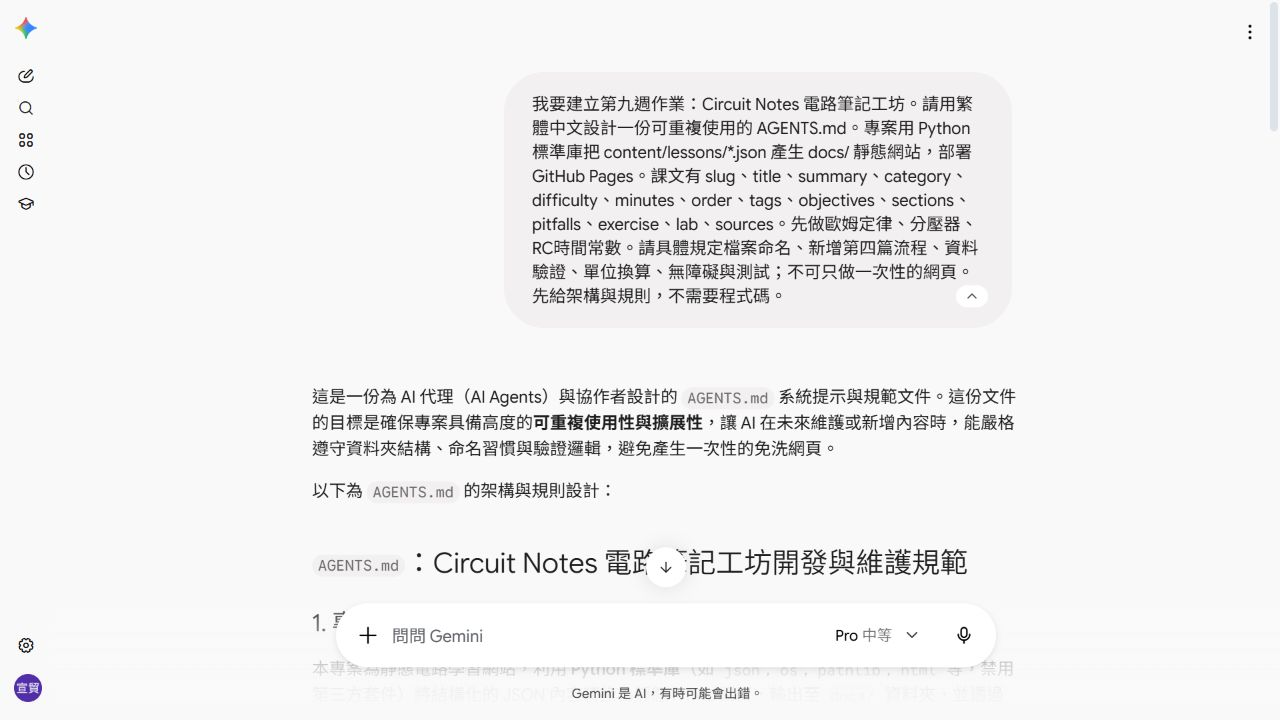


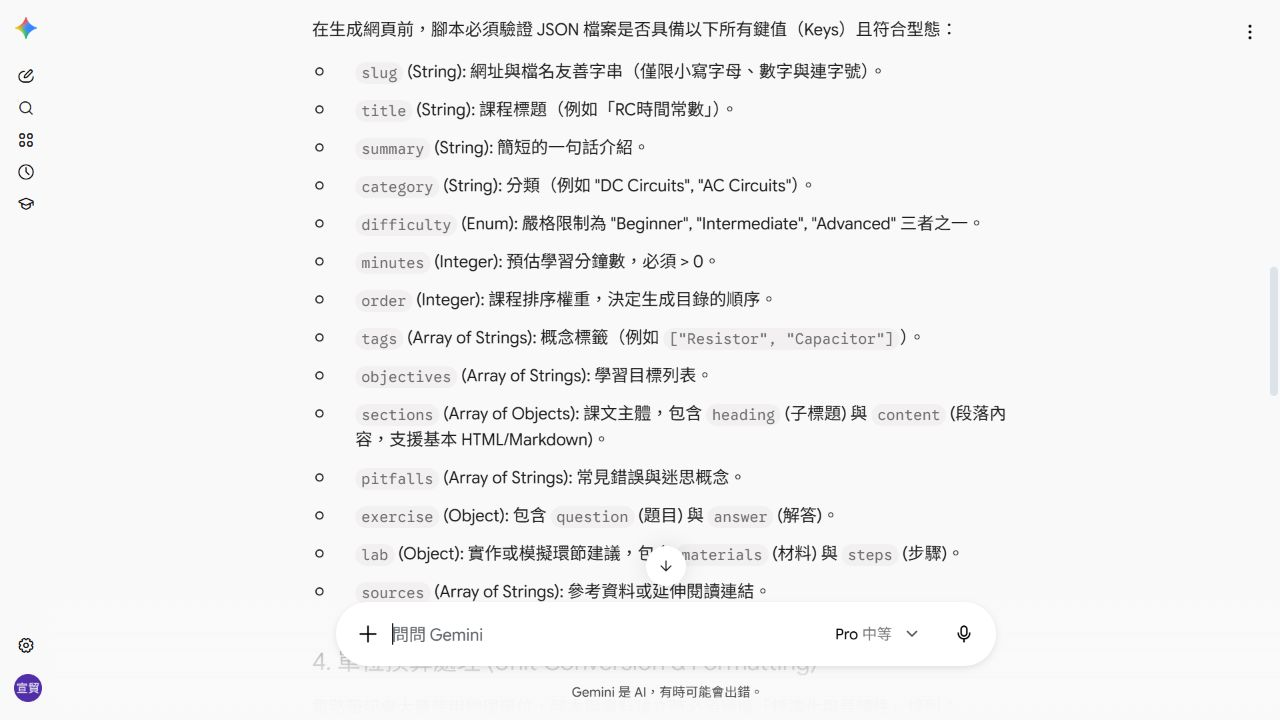


## 整合與修正

Gemini 首輪建議中的檔名包含序號、`difficulty` 使用英文、段落使用 `content`，而 `lab` 採物件形式，與這個專案要維持的固定格式不同。整合時統一為以下規則：

| 項目 | 最終專案格式 |
| --- | --- |
| 檔名 | `<slug>.json`，與資料內的 `slug` 相同，不另外加序號 |
| 難度 | `入門` 或 `進階` |
| 段落內容 | `sections[].paragraphs` 字串陣列，公式另放選填的 `formula` |
| 互動種類 | `lab` 只使用 `ohm`、`divider`、`rc`、`none` 四種字串 |

最終源檔是依專案需求整合、修正後的版本，並非把 Gemini 首輪回覆全部直接貼上，也不將程式描述為使用者逐行手打。

另外修正了兩個具體問題：分壓器 SVG 補上 R₂ 元件標示；規則頁的 RC 示範連結依 RC 課文是否存在決定是否顯示，避免只有前兩篇內容時產生不存在的連結。

驗收程式設計了十項檢查：資料 schema 與預期內容、拒絕無效資料、檔名與排序、HTML 跳脫、內部路徑與錨點、規則副本一致、重複建置一致性、從兩篇擴充到第三篇 RC、只新增 JSON 就加入第四篇課文，以及 JavaScript 計算與邊界值。後兩個擴充實驗分別檢查「2 → 3 篇」與「第四課」是否沿用既有規則與產生器；這些是檢查範圍，實際結果以下方紀錄為準。


### 實際驗收紀錄

以下原樣收錄本次 `work/verification.json` 的結果，與後續重新執行筆記本時產生的輸出分開閱讀。

```text
{
  "date": "2026-11-06",
  "status": "passed",
  "tests_passed": 10,
  "tests_total": 10,
  "python": "3.13.7",
  "node": "24.22.1",
  "command": "python build.py; python tests/check_project.py",
  "checks": [
    "JSON 欄位與錯誤資料拒絕、HTML 字元跳脫、內部檔案與錨點連結",
    "規則副本一致與可重現建置",
    "隔離副本中由兩篇新增 RC 第三篇，首頁、導覽、課文頁自動更新",
    "隔離副本新增第四篇 lab:none，不修改核心程式即可產生完整頁面",
    "JavaScript 歐姆定律、帶負載分壓、RC 計算與無效輸入邊界"
  ],
  "browser_checks": [
    "首頁搜尋 RC 後只顯示一篇；無結果提示與清除篩選正常",
    "收藏 RC、重新載入後只看收藏仍顯示一篇",
    "RC 滑桿 t/τ=5 時，畫面顯示 4.97 V、99.3%",
    "練習解答可展開並顯示運算步驟",
    "手機首頁與課文可視寬度375px，內容寬度375px，無水平溢出"
  ],
  "remote_checks": [
    "GitHub assets/app.js 與本機 UTF-8 內容及 SHA-256 完全一致，未截斷",
    "公開 Repository 初版24個對應檔案逐檔比對一致，無缺檔",
    "GitHub Pages 首次部署完成 Success，公開首頁已實際開啟"
  ],
  "limitations": [
    "指定影片已核對標題，但 YouTube 未提供可匯出的逐字稿，未宣稱完整觀看",
    "本驗收紀錄來自本機執行；不是 Colab 伺服器執行紀錄"
  ]
}
```

## 網站畫面

以下是本次網站的實際畫面；圖像只記錄擷取當下狀態，互動結果仍可透過後續程式與網頁驗證。

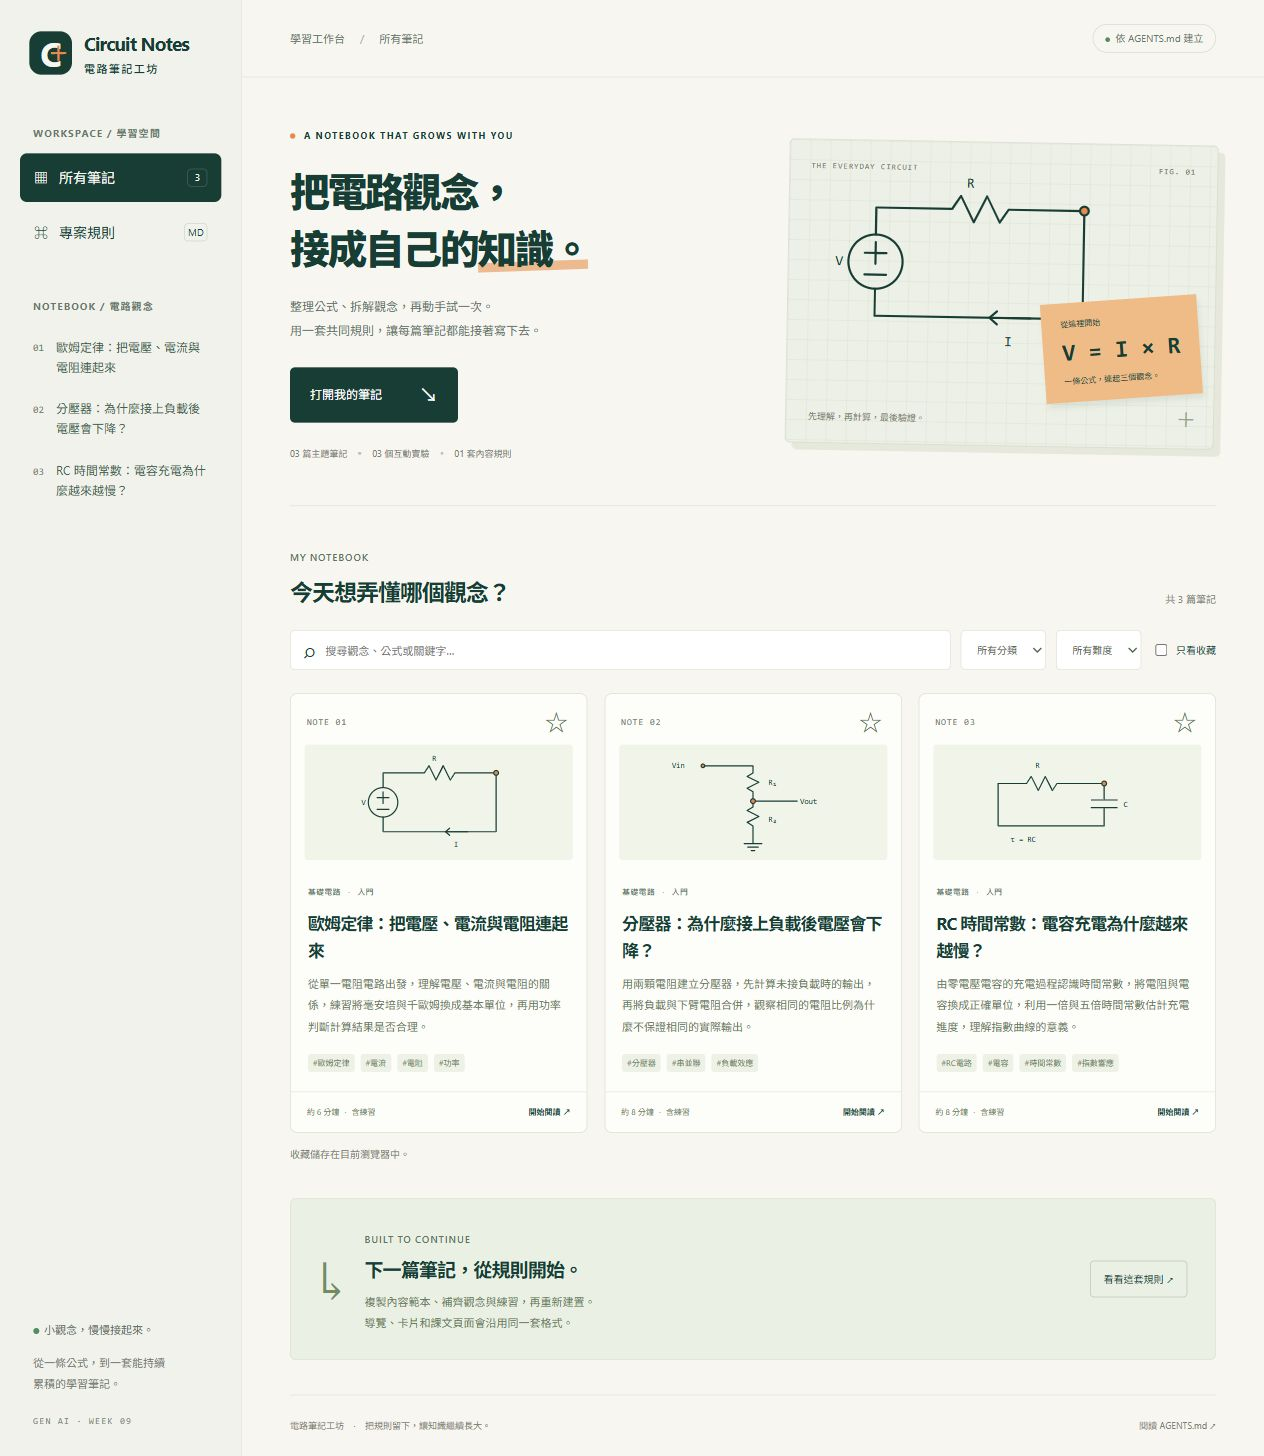


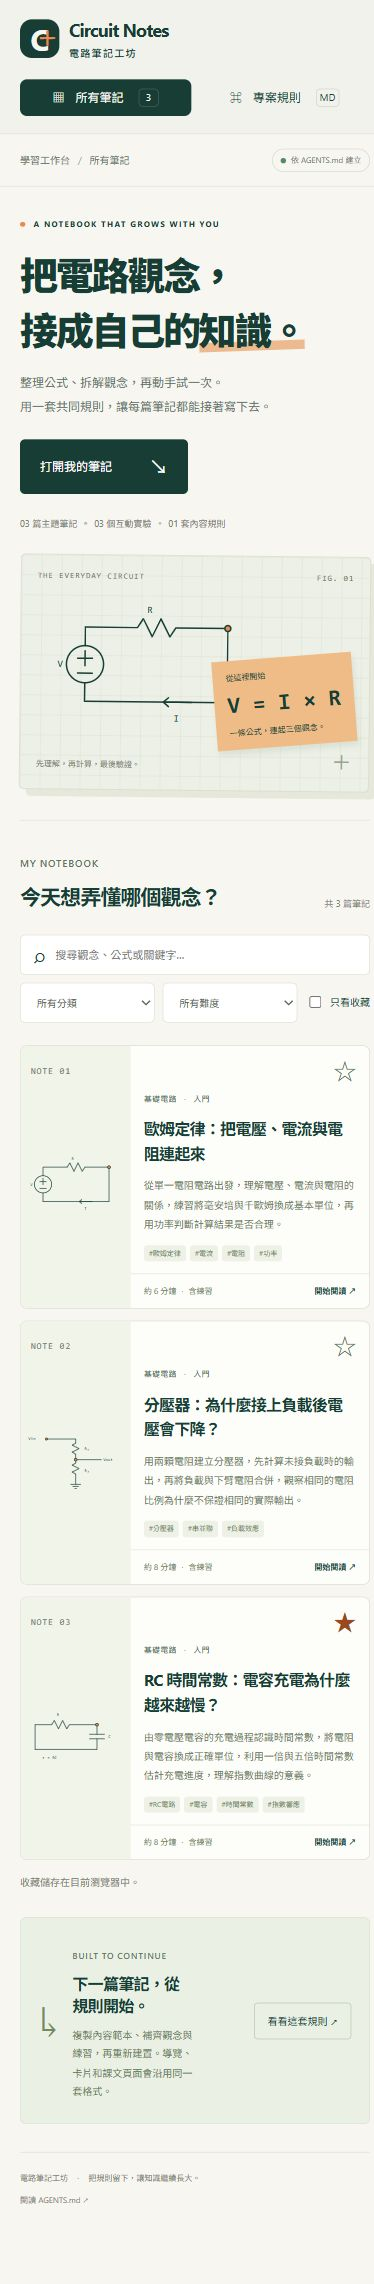


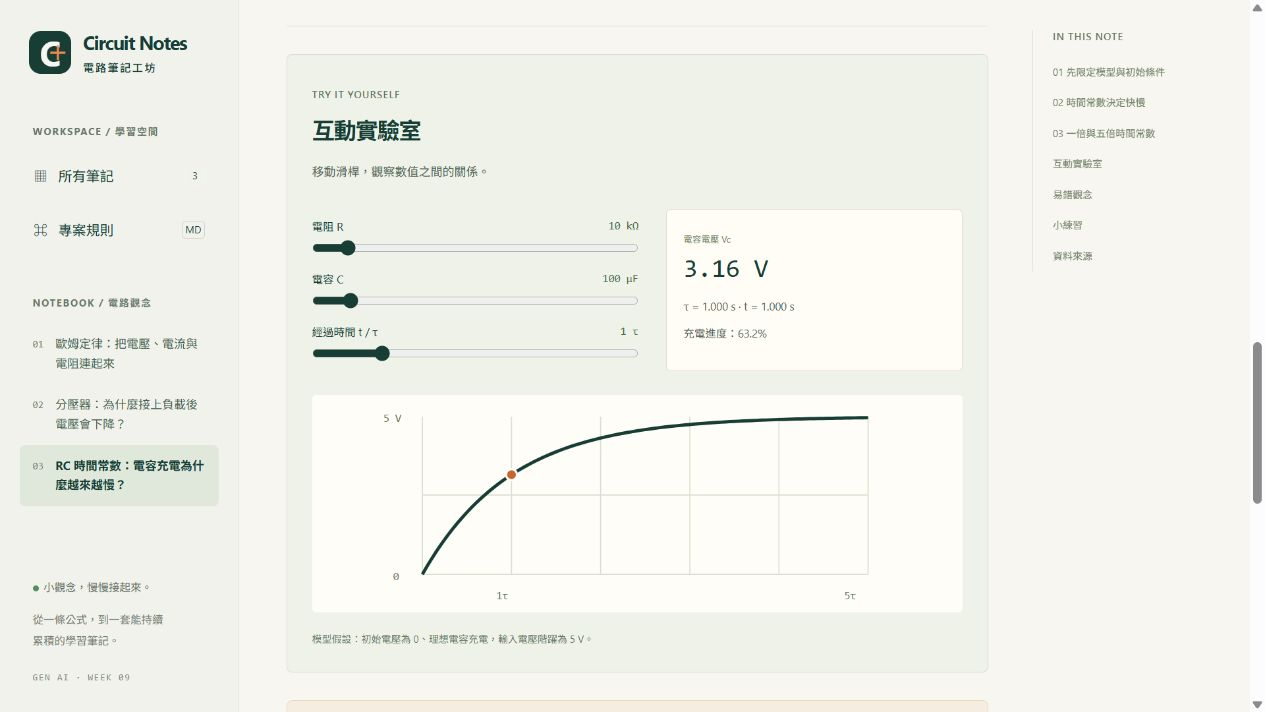


## 1. 準備獨立的專案目錄

重建目錄預設為目前工作目錄下的 `circuit-notes-colab/`。後續寫檔函式先檢查路徑位於此目錄內，避免絕對路徑或 `..` 把檔案寫到其他位置。重複執行會更新此專案目錄中同名的源檔；不執行遞迴刪除。


In [ ]:
from pathlib import Path
import json
import subprocess
import sys

BASE_DIRECTORY = Path.cwd().resolve()
PROJECT_ROOT = (BASE_DIRECTORY / "circuit-notes-colab").resolve()
assert PROJECT_ROOT.parent == BASE_DIRECTORY, "專案必須是目前目錄的直接子目錄，不能指向外部連結"
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

def write_file(relative_path, content):
    relative = Path(relative_path)
    assert not relative.is_absolute() and ".." not in relative.parts, "只允許專案內的相對路徑"
    target = (PROJECT_ROOT / relative).resolve()
    assert target.is_relative_to(PROJECT_ROOT), "寫入目標必須位於專案目錄內"
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(content, encoding="utf-8", newline="\n")
    print(f"已寫入 {relative.as_posix()}")

print("專案目錄：", PROJECT_ROOT)


## 2. 寫入可閱讀的完整源檔

每個源檔各有獨立儲存格。以下直接保存文字內容，不使用 base64 或壓縮字串隱藏程式碼；`docs/` 網頁會在下一節由建置程式產生。

### `AGENTS.md`

In [ ]:
write_file('AGENTS.md', r'''# Circuit Notes｜電路筆記工坊：AI 協作規則

本文件是整個 Repository 的共同開發規則。修改前先讀本文件，再查看 `README.md`、`content/template.json` 與一篇既有課文。遇到規則無法處理的需求，先說明影響，避免默默改掉整個網站的架構。

## 1. 專案目的與讀者

- 建立供資電相關科系初學者使用的繁體中文電路知識庫。
- 每一課都要讓讀者能掌握一個觀念、理解公式的成立條件，並完成一題可以驗算的練習。
- 內容採用同一份資料格式，由共用模板產生頁面。新增課文通常只需要新增一個 JSON 檔，不必重新設計網頁。
- 網站是教學示例，不宣稱讀者或作者已進行未被記錄的實驗。AI 協作紀錄與實際測試結果必須如實呈現。

## 2. 檔案結構與修改位置

```text
AGENTS.md                    # 本規則；改規則時須同步檢查受影響的程式
README.md                    # 安裝、瀏覽與 GitHub Pages 發布方式
docs-authoring.md             # 新增內容流程與可重用的 AI 提示詞
build.py                     # Python 標準函式庫的靜態網站產生器
content/
  template.json              # 新課文資料模板，不當成正式課文發布
  lessons/
    ohms-law.json
    voltage-divider.json
    rc-time-constant.json
assets/
  styles.css                 # 全站樣式
  app.js                     # 搜尋、篩選、書籤與互動實驗
tests/
  check_project.py           # 專案驗收程式
docs/                        # build.py 產生，GitHub Pages 的發布目錄
  index.html
  rules.html
  404.html
  lessons/<slug>.html
```

**不可直接修改 `docs/` 內的產出檔。** 先修改 `content/`、`assets/` 或 `build.py`，再重新執行建置，並一併提交產出。不要把暫存檔、憑證、個人瀏覽器資料或 API 金鑰加入 Repository。

## 3. 命名與資料格式

- 一篇課文一個檔案：`content/lessons/<slug>.json`。
- `slug` 使用小寫英文字母、數字與連字號，例如 `rc-time-constant`；必須與檔名一致，不可與既有課文重複。
- 檔案採 UTF-8、有效 JSON、兩格縮排。不要加入註解或尾逗號。
- 保留以下欄位名稱；一般加課文不要自行增加新的資料結構。

| 欄位 | 格式與用途 |
| --- | --- |
| `slug` | 唯一識別名稱，同時用於網址 |
| `title` | 繁體中文課名，直接說明本課主題 |
| `summary` | 能獨立閱讀的簡介，建議約 45～85 個中文字 |
| `category` | 分類；本專案既有內容使用 `基礎電路` |
| `difficulty` | 難度；既有內容使用 `入門` |
| `minutes` | 正整數，預估閱讀與操作時間，不冒稱實際量測時間 |
| `order` | 整數，決定課文的預設排列；新增時查看現有值 |
| `tags` | 字串陣列，採具體關鍵詞，例如 `電阻`、`分壓` |
| `objectives` | 字串陣列，以讀者讀完後能完成的事描述學習目標 |
| `sections` | 段落物件陣列，每個物件有 `heading`、`paragraphs`，可加 `formula` |
| `sections[].paragraphs` | 純文字字串陣列，不放 HTML 或可執行內容 |
| `sections[].formula` | 選填的純文字公式，使用 Unicode，例如 `τ = R × C` |
| `pitfalls` | 字串陣列，指出易錯觀念與使用限制 |
| `exercise` | 物件，必須包含 `question`、`hint`、`answer` 三個字串 |
| `lab` | 僅使用 `ohm`、`divider`、`rc` 或 `none` |
| `sources` | 來源物件陣列，每個物件包含 `label` 與可開啟的 `url` |

欄位範例：RC 課文使用 `"slug": "rc-time-constant"`、`"lab": "rc"`，觀念段落的 `formula` 可寫 `"τ = R × C；Vc(t) = Vs × (1 − e^(−t/τ))"`。完整 JSON 請以 `content/template.json` 與既有課文作為格式範例，不要將模板直接當正式文章發布。

## 4. 每篇課文的內容標準

頁面順序固定為：**簡介 → 學習目標 → 觀念與公式 → 互動實驗（若有）→ 易錯提醒 → 小練習 → 參考來源**。

- 課文一般分成 3～4 個觀念段落；每段先說明物理意義，再給必要公式或數值例子。
- 首次出現變數時說明其意義與單位；區分 Ω、kΩ、F、μF、s、ms。計算時先換成一致的 SI 單位。
- 寫清楚模型假設。例如理想分壓公式的輸出端未接負載；RC 充電曲線需要說明初始電壓與輸入條件。
- 每篇至少有一題數值明確的小練習，提示與答案分開。答案包含運算步驟、合理有效位數與單位。
- 來源優先採大學公開教材、元件廠商官方教學或官方技術文件。開啟並核對來源是否真的支持該段內容；不要只貼搜尋結果頁或無關首頁。
- 外部內容應以自己的文字重述。不可複製大段文章、虛構實驗結果、捏造引用或把 AI 回覆當成已核實來源。
- 一般教學內容以文字與既有互動元件完成，不引入追蹤服務、登入機制、付費 API 或外部 CDN。

## 5. 視覺、互動與無障礙

- 品牌名稱為「Circuit Notes｜電路筆記工坊」。整體風格像清楚、安靜的工程筆記，優先呈現閱讀與練習內容。
- 主色墨綠 `#173d35`、底色米白 `#f7f6f0`、輔色橘 `#e78a51`。使用既有 CSS 變數與共用元件，避免每篇自行配色。
- 採系統字體，中文字體可使用本機可用的無襯線字體。文字須保持足夠對比，不能只靠顏色表達狀態。
- 桌面與手機都須可閱讀；窄螢幕下欄位能自然換行，不能以固定寬度造成水平溢出。
- 使用語意化標籤、合理標題層級、可辨識的連結文字。所有表單控制都有標籤，按鈕可用鍵盤操作並保留焦點樣式。
- 首頁搜尋涵蓋課名、簡介與標籤；分類與難度可組合使用，無結果時要顯示清楚提示。
- 書籤只存於瀏覽器 `localStorage`。儲存不可用時，網站的閱讀與篩選仍須能運作。
- 互動實驗的輸入值與輸出結果須附單位。處理空值、無效數值與不合理的除數，避免顯示 `NaN` 或 `Infinity`。

## 6. AI 新增一篇課文的固定流程

1. 讀取本文件、`content/template.json` 與主題最接近的既有 JSON。
2. 檢查現有 slug、排序值與來源，決定新課文的範圍、假設和練習。
3. 複製模板為 `content/lessons/<new-slug>.json`，填完所有欄位並核對公式、單位和來源。
4. 若既有互動元件適用，選用對應的 `lab`；不適用就設為 `none`。不要為了放文章而改造互動 API。
5. 執行 `python build.py` 重新產生網站，再執行 `python tests/check_project.py`。
6. 透過本機 HTTP 伺服器檢查首頁、新課文、導覽、搜尋、篩選、書籤及小練習。若無瀏覽器可用，要明確記錄此限制。
7. 查看 Git 差異，確認只包含新文章與必要產出，回報新增檔案、來源、執行過的檢查和仍未驗證的項目。

延伸範例：新增 `rc-time-constant.json` 後，共用產生器應建立 `docs/lessons/rc-time-constant.html`，首頁自動出現 RC 課文、標籤與閱讀連結；其他兩課不需要重寫。未來新增串聯電阻課文時，同樣沿用此流程並選 `lab: "none"`。

## 7. 修改邊界與驗收

- 只加內容時，通常只改 `content/lessons/` 與重新產生的 `docs/`。
- 只有新的顯示需求無法由既有格式表達時，才修改 schema、產生器或共用樣式；此時一併更新模板、文件與相關驗證。
- 不刪除既有課文、不任意改 slug；若需更名，先處理舊連結與導覽。
- 不在新增文章的任務中順便更換框架、套件、配色、發布方式或整站文案。
- 不執行未經要求的部署、變更分享權限、刪除 Repository 或暴露憑證。已被使用者明確授權的發布任務可在完成檢查後進行。

基本驗收命令：

```bash
python build.py
python tests/check_project.py
python -m http.server 8000 --directory docs
```

最後一個命令只啟動預覽，不代表已公開。發布前須確認：資料合法、內部連結存在、產出與來源一致、互動值可以驗算、手機與鍵盤可操作；部署後再核對真實的 Repository 與網頁網址。沒有執行的檢查不能寫成通過。
''')


### `README.md`

In [ ]:
write_file('README.md', r'''# Circuit Notes｜電路筆記工坊

一個以繁體中文整理基礎電路觀念的靜態知識庫。每篇筆記都包含學習目標、觀念與公式、易錯提醒、練習及來源；部分課文附有可調參數的互動實驗。

[開啟公開網站](https://mao0621.github.io/circuit-notes-hw9/) · [GitHub Repository](https://github.com/mao0621/circuit-notes-hw9)

本專案的重點是建立可重用的內容規則：AI 先閱讀 [AGENTS.md](AGENTS.md)，依固定 JSON 格式新增課文，再由共用模板產生網頁，無須每次重新設計版面。第九週作業主題為「建立自己的 AGENTS.md 或 CLAUDE.md」。

## 目前內容

| 課文 | 內容 | 互動 |
| --- | --- | --- |
| 歐姆定律 | 電壓、電流、電阻與功率 | 改變電壓與電阻，查看電流和功率 |
| 分壓器 | 理想分壓與負載效應 | 調整電阻與輸入，觀察輸出變化 |
| RC 時間常數 | 充電曲線與單位換算 | 調整 R、C 與時間，查看充電電壓 |

第三篇 RC 課文用來示範同一套規則的延伸方式。本次建立三篇內容作為可運作的示例，並未宣稱這些頁面來自過去的課堂實驗。

## 環境與本機瀏覽

需要 Python 3；建置只使用標準函式庫，不需安裝第三方套件。網頁使用原生 HTML、CSS、JavaScript，不依賴外部 CDN。

在專案根目錄執行：

```bash
python build.py
python tests/check_project.py
python -m http.server 8000 --directory docs
```

啟動後開啟 `http://localhost:8000`。停止預覽時，在啟動伺服器的終端機按 `Ctrl+C`。

`build.py` 會由 `content/lessons/*.json` 與 `assets/` 重新產生 `docs/`。請修改來源檔，不要直接修改產出的 HTML。若修改後沒有重建，公開網站仍會顯示舊內容。

## 新增一篇內容

1. 閱讀 [AGENTS.md](AGENTS.md) 的資料格式與內容標準。
2. 複製 `content/template.json`，另存為 `content/lessons/<slug>.json`。
3. 填入全部欄位，核對公式、單位、練習與來源。選用既有互動類型，或設為 `none`。
4. 執行建置、驗收與預覽，確認首頁與新文章都可正常瀏覽。
5. 提交來源檔與更新後的 `docs/`。

可直接交給 AI 的提示詞，以及 RC 延伸示範，見 [docs-authoring.md](docs-authoring.md)。

## 發布到 GitHub Pages

這是一般 Repository 的靜態網站，不需要自訂網域或後端服務。發布狀態與實際連結請以本次發布結果為準。

1. 在自己的 GitHub 帳號建立公開 Repository，將本專案完整上傳到預設分支。確認 Repository 根目錄有 `AGENTS.md`，且 `docs/index.html` 已建置。
2. 開啟 Repository 的 **Settings → Pages**。
3. 在 **Build and deployment** 選擇 **Deploy from a branch**。
4. 選擇實際上傳的分支（通常為 `main`），資料夾選 **`/docs`**，再儲存。
5. 等待 GitHub Pages 部署完成；以 Pages 頁面顯示的真實網址開啟首頁、任一課文及規則頁。不要把預測網址當成成功部署的證明。

頁面採相對路徑，可放在 GitHub Pages 的 Repository 子路徑。每次改內容後，重新建置並推送 `docs/`；Pages 會依其設定部署新的提交。

| 繳交所需項目 | 位置或狀態 |
| --- | --- |
| 專案簡介 | 本 README 首段 |
| GitHub Repository 連結 | [mao0621/circuit-notes-hw9](https://github.com/mao0621/circuit-notes-hw9) |
| 網頁連結 | [電路筆記工坊](https://mao0621.github.io/circuit-notes-hw9/) |
| AI 開發規則 | [AGENTS.md](AGENTS.md) |
| 如何持續新增內容 | [docs-authoring.md](docs-authoring.md) |

## 資料與安全

書籤保存在使用者自己的瀏覽器 `localStorage`，不會上傳到伺服器；清除瀏覽資料或更換裝置後不保證保留。若瀏覽器不允許儲存，閱讀功能仍可使用。

Repository 中不得放入 GitHub 權杖、API 金鑰、密碼、個人瀏覽器設定或其他人的資料。發布公開 Repository 前，應檢查待提交的檔案。開發與協作紀錄只記錄實際發生的對話、修改與檢查，不虛構 Gemini 回覆、截圖、測試結果或個人實驗經歷。
''')


### `docs-authoring.md`

In [ ]:
write_file('docs-authoring.md', r'''# 持續新增內容：規則如何幫助 AI 接手

`AGENTS.md` 把「要教什麼、資料放哪裡、頁面如何產生、完成後如何驗收」寫成共同規則。AI 接手時先讀規則，再依模板填資料，即可沿用既有導覽、版面與互動元件。內容資料與網頁樣式分開，能降低每新增一頁就出現不同風格或漏掉練習、來源的機會。

## 本次的 RC 延伸示範

本次建立歐姆定律、分壓器及 RC 時間常數三篇課文，將第三篇 RC 課文作為規則延伸的示例。以下是結構上的新增方式，不代表三篇文章曾由不同日期或不同人製作，也不代表已完成所有瀏覽器檢查。

| 項目 | 歐姆定律、分壓器 | 加入 RC 課文後 |
| --- | --- | --- |
| 課文資料 | `ohms-law.json`、`voltage-divider.json` | 加入 `rc-time-constant.json` |
| 內容格式 | 同一份 schema | 沿用原有欄位 |
| 觀念呈現 | 目標、段落、公式、提醒、練習、來源 | 保留相同順序 |
| 互動類型 | `ohm`、`divider` | 選用既有規格中的 `rc` |
| 課文路徑 | 由 slug 產生 | 產生 `docs/lessons/rc-time-constant.html` |
| 首頁、導覽與樣式 | 共用模板 | 由建置結果更新，不需另寫 RC 首頁卡片 |

RC 內容必須說明 `τ = R × C`、初始電壓為 0 的理想充電條件，以及 `Vc(t) = Vs × (1 − e^(−t/τ))`。例如 R = 10 kΩ、C = 100 μF，時間常數為 1 s；經過一個時間常數後，電容電壓約為輸入電壓的 63.2%。這個數值可作為課文與互動結果的交叉檢查，不能直接取代程式測試。

## 可重用提示詞一：只新增內容

以下文字可以直接交給日後接手這個 Repository 的 AI：

```text
請先閱讀 Repository 根目錄的 AGENTS.md、README.md、content/template.json，
以及 content/lessons/ohms-law.json。

請為 Circuit Notes｜電路筆記工坊新增一篇「串聯電阻」課文。
slug 使用 series-resistance，lab 使用 none，維持現有 schema、配色、導覽與版面。
內容需包含串聯電阻的等效電阻、相同電流條件、電壓分配、常見誤解，
並設計一題有步驟與單位的數值練習。

請查核至少一份具體的官方或大學公開教材來源，並將來源列入 sources。
不要直接修改 docs/ 中的 HTML；由新增的 JSON 透過 python build.py 產生頁面。
執行 python tests/check_project.py，再檢查新頁、首頁連結與搜尋結果。
最後列出修改檔案、執行結果，以及未能完成的檢查，不要捏造通過紀錄。
```

這段提示詞只要更換主題、slug 與教學重點，便能沿用到其他課文。它要求 AI 讀取專案規則與現有資料，而非每次從零決定架構。

## 可重用提示詞二：需要新增互動能力

```text
請先閱讀 AGENTS.md、build.py、assets/app.js、content/template.json，
以及目前測試，說明現有 lab 類型的資料與呈現方式。

我想新增「兩個並聯電阻」課文，並讓讀者輸入 R1、R2，
觀察 Req = R1 × R2 / (R1 + R2) 的等效電阻。
請先判斷這個需求是否能由既有 lab 類型表達；若不能，
在保留原有課文行為的前提下新增最小必要的互動類型。

同步更新 AGENTS.md、模板、產生器、互動程式與相關測試，
加入正數、空值、無效輸入與單位處理，並檢查原有三個互動仍可使用。
公式與課文內容須有核實來源，禁止直接修改 docs/ 的產出檔。
執行建置與驗收，預覽新頁與既有頁面，回報變更範圍與實際檢查結果。
```

第二個提示詞適用於共用能力確實不足的情況。AI 必須同步修改規則與實作，避免新增欄位後只有新頁面能使用，或讓後續接手者不知道新的格式。

## 交付前的實際檢查

```bash
python build.py
python tests/check_project.py
python -m http.server 8000 --directory docs
```

預覽時依序檢查首頁、新課文、搜尋、分類、書籤、小練習與互動值；再以窄螢幕與鍵盤檢查可用性。若環境無法開啟瀏覽器，必須記錄限制，不得把靜態檔案檢查描述成完整的視覺驗收。公開後另以 GitHub Pages 真實網址核對結果。
''')


### `content/template.json`

In [ ]:
write_file('content/template.json', r'''{
  "slug": "_template",
  "title": "填寫課文標題：明確指出要回答的問題",
  "summary": "填寫四十五至八十五字的摘要，說明本篇範圍、學習方法與讀者讀完能解決的具體問題；不要只重複標題，也不要聲稱尚未做過的實驗。",
  "category": "基礎電路",
  "difficulty": "入門",
  "minutes": 6,
  "order": 4,
  "tags": ["填寫主題標籤", "填寫關鍵概念"],
  "objectives": ["以可檢查的動詞寫出第一個學習目標。", "寫出第二個學習目標。"],
  "sections": [
    {"heading": "定義與模型", "paragraphs": ["填寫變數定義、單位及適用條件。"], "formula": "填寫 Unicode 純文字公式；不需要公式時刪除此欄位。"},
    {"heading": "觀念與推導", "paragraphs": ["填寫主要觀念，說明為什麼成立。"]},
    {"heading": "數字例子與檢查", "paragraphs": ["給出可以驗算的例題，註明結果與單位。"]}
  ],
  "pitfalls": ["指出一個常見錯誤及修正方法。", "指出模型的限制。"],
  "exercise": {"question": "寫一題具明確條件與單位的練習。", "hint": "提示計算方向，不直接重複答案。", "answer": "列出代入步驟、計算結果與單位。"},
  "lab": "ohm",
  "sources": [{"label": "填寫已查核的原始來源名稱", "url": "https://openstax.org/books/physics/pages/19-1-ohms-law"}]
}
''')


### `.gitignore`

In [ ]:
write_file('.gitignore', r'''__pycache__/
*.py[cod]
.venv/
.env
.env.*
!.env.example
.DS_Store
Thumbs.db
*.log

''')


### `assets/app.js`

In [ ]:
write_file('assets/app.js', r'''"use strict";

// Pure calculations share the exact same units as the displayed controls.
const CircuitMath = Object.freeze({
  ohm(voltage, resistance) {
    if (!Number.isFinite(voltage) || voltage < 0 || !Number.isFinite(resistance) || resistance <= 0) return null;
    return { currentMA: voltage / resistance * 1000, powerMW: voltage ** 2 / resistance * 1000 };
  },
  divider(vin, r1, r2, load) {
    if (![vin, r1, r2, load].every(Number.isFinite) || vin < 0 || Math.min(r1, r2, load) <= 0) return null;
    const parallel = r2 * load / (r2 + load);
    const unloaded = vin * r2 / (r1 + r2);
    const loaded = vin * parallel / (r1 + parallel);
    return { parallel, unloaded, loaded, dropPercent: unloaded > 0 ? (1 - loaded / unloaded) * 100 : 0 };
  },
  rc(rKOhm, cMicroF, multiples) {
    if (![rKOhm, cMicroF, multiples].every(Number.isFinite) || Math.min(rKOhm, cMicroF) <= 0 || multiples < 0) return null;
    const tau = rKOhm * 1000 * cMicroF * 1e-6;
    const fraction = 1 - Math.exp(-multiples);
    return { tau, time: tau * multiples, voltage: 5 * fraction, percent: 100 * fraction };
  }
});
if (typeof module !== "undefined" && module.exports) module.exports = CircuitMath;

if (typeof document !== "undefined") {
  const $ = (id) => document.getElementById(id);
  const key = "circuit-notes:bookmarks:v1";
  let saved = new Set();
  let storageAvailable = true;
  try {
    const parsed = JSON.parse(localStorage.getItem(key) || "[]");
    if (Array.isArray(parsed)) saved = new Set(parsed.filter((x) => typeof x === "string"));
  } catch (_) { storageAvailable = false; }

  function storageNote() {
    if ($("storage-note") && !storageAvailable) $("storage-note").textContent = "此瀏覽器無法保存收藏；本次開啟期間仍可收藏與篩選。";
  }
  function paintBookmarks() {
    document.querySelectorAll("[data-bookmark]").forEach((button) => {
      const marked = saved.has(button.dataset.bookmark);
      button.setAttribute("aria-pressed", String(marked));
      button.querySelector("span").textContent = marked ? "★" : "☆";
    });
  }
  function filterNotes() {
    if (!$("search")) return;
    const query = $("search").value.trim().toLocaleLowerCase();
    const tokens = query.split(/\s+/).filter(Boolean);
    let visible = 0;
    document.querySelectorAll(".note-card").forEach((card) => {
      const matches = tokens.every((token) => card.dataset.search.toLocaleLowerCase().includes(token))
        && (!$("category").value || card.dataset.category === $("category").value)
        && (!$("difficulty").value || card.dataset.difficulty === $("difficulty").value)
        && (!$("saved-only").checked || saved.has(card.dataset.slug));
      card.hidden = !matches;
      if (matches) visible++;
    });
    $("result-count").textContent = `共 ${visible} 篇筆記`;
    $("empty-state").hidden = visible > 0;
  }
  document.querySelectorAll("[data-bookmark]").forEach((button) => {
    button.addEventListener("click", () => {
      const slug = button.dataset.bookmark;
      saved.has(slug) ? saved.delete(slug) : saved.add(slug);
      try { localStorage.setItem(key, JSON.stringify([...saved])); }
      catch (_) { storageAvailable = false; storageNote(); }
      paintBookmarks(); filterNotes();
    });
  });
  if ($("search")) {
    $("search").addEventListener("input", filterNotes);
    ["category", "difficulty", "saved-only"].forEach((id) => $(id).addEventListener("change", filterNotes));
    $("reset-filters").addEventListener("click", () => {
      $("search").value = ""; $("category").value = ""; $("difficulty").value = ""; $("saved-only").checked = false;
      filterNotes(); $("search").focus();
    });
    filterNotes();
  }
  paintBookmarks(); storageNote();

  if ($("copy-rules")) {
    $("copy-rules").addEventListener("click", async () => {
      try {
        await navigator.clipboard.writeText($("rules-text").textContent);
        $("copy-rules").textContent = "已複製 ✓";
        $("copy-status").textContent = "已複製 AGENTS.md";
      } catch (_) {
        $("copy-rules").textContent = "請下載規則檔";
        $("copy-status").textContent = "瀏覽器無法複製，請使用旁邊的下載連結。";
      }
    });
  }

  const lab = document.querySelector("[data-lab]");
  if (lab) {
    const value = (id) => Number($(id).value);
    const f = (number, digits = 2) => number.toLocaleString("en-US", { maximumFractionDigits: digits, minimumFractionDigits: digits });
    function updateLab() {
      lab.querySelectorAll("input[type=range]").forEach((input) => {
        $(`${input.id}-value`).textContent = `${Number(input.value).toLocaleString("en-US")} ${input.dataset.unit}`;
      });
      let result;
      if (lab.dataset.lab === "ohm") {
        result = CircuitMath.ohm(value("voltage"), value("resistance"));
        $("lab-result").innerHTML = result ? `<small>流過電阻的電流</small><strong>${f(result.currentMA)} mA</strong><p>電阻消耗功率：${f(result.powerMW)} mW</p><p>I = V / R · P = V² / R</p>` : "請輸入有效的電壓與正電阻。";
      } else if (lab.dataset.lab === "divider") {
        result = CircuitMath.divider(value("vin"), value("r1"), value("r2"), value("load"));
        $("lab-result").innerHTML = result ? `<small>帶負載的輸出電壓</small><strong>${f(result.loaded)} V</strong><p>無負載：${f(result.unloaded)} V</p><p>R₂ ∥ Rᴸ = ${f(result.parallel)} Ω</p><p>相對無負載下降 ${f(result.dropPercent, 1)}%</p>` : "請使用正值電阻與有效的輸入電壓。";
      } else if (lab.dataset.lab === "rc") {
        result = CircuitMath.rc(value("rc-r"), value("rc-c"), value("time"));
        $("lab-result").innerHTML = result ? `<small>電容電壓 Vc</small><strong>${f(result.voltage)} V</strong><p>τ = ${f(result.tau, 3)} s · t = ${f(result.time, 3)} s</p><p>充電進度：${f(result.percent, 1)}%</p>` : "請使用正值電阻、電容與非負時間。";
        const path = Array.from({ length: 101 }, (_, i) => {
          const x = 42 + 410 * i / 100;
          const y = 165 - 145 * (1 - Math.exp(-5 * i / 100));
          return `${i ? "L" : "M"}${x.toFixed(2)},${y.toFixed(2)}`;
        }).join(" ");
        $("rc-curve").setAttribute("d", path);
        if (result) {
          $("rc-point").setAttribute("cx", String(42 + 410 * value("time") / 5));
          $("rc-point").setAttribute("cy", String(165 - 145 * result.percent / 100));
          $("rc-chart").setAttribute("aria-label", `RC充電曲線，時間為 ${f(result.time, 3)} 秒，電容電壓 ${f(result.voltage)} V。`);
        }
      }
    }
    lab.querySelectorAll("input[type=range]").forEach((input) => input.addEventListener("input", updateLab));
    updateLab();
  }
}
''')


### `assets/favicon.svg`

In [ ]:
write_file('assets/favicon.svg', r'''<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 64 64"><rect width="64" height="64" rx="18" fill="#173d35"/><path d="M42 19a18 18 0 1 0 0 26" fill="none" stroke="#f7f6f0" stroke-width="7"/><path d="M45 23v18m-9-9h18" stroke="#e78a51" stroke-width="5"/></svg>
''')


### `assets/styles.css`

In [ ]:
write_file('assets/styles.css', r'''@charset "UTF-8";
:root{--ink:#173d35;--paper:#f7f6f0;--accent:#e78a51;--muted:#66736c;--line:#dedfd5;--white:#fff;--pale:#eaf0e8;--sidebar:242px}
*{box-sizing:border-box}html{scroll-behavior:smooth;scroll-padding-top:30px}body{margin:0;background:var(--paper);color:var(--ink);font:15px/1.75 -apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans TC","Microsoft JhengHei",sans-serif}a{color:inherit;text-decoration:none}button,input,select{font:inherit}button,a,input,select,summary{-webkit-tap-highlight-color:transparent}button{color:inherit}a:focus-visible,button:focus-visible,input:focus-visible,select:focus-visible,summary:focus-visible{outline:3px solid #a14819;outline-offset:4px}button{cursor:pointer}::selection{background:#f3c6a7}h1,h2,h3,p{margin:0}h1,h2,h3{line-height:1.4;letter-spacing:-.045em}svg{max-width:100%}[hidden]{display:none!important}.sr-only{position:absolute;width:1px;height:1px;padding:0;margin:-1px;overflow:hidden;clip:rect(0,0,0,0);white-space:nowrap;border:0}.skip-link{position:fixed;top:10px;left:10px;padding:10px 20px;background:var(--ink);color:white;z-index:20;transform:translateY(-160%)}.skip-link:focus{transform:none}
.sidebar{position:fixed;width:var(--sidebar);top:0;bottom:0;border-right:1px solid var(--line);padding:30px 20px;background:#f1f2eb;display:flex;flex-direction:column;z-index:5;overflow:auto}.brand{display:flex;align-items:center;gap:12px;margin:0 9px 48px;font-size:19px;font-weight:750;line-height:1.4;letter-spacing:-.045em;white-space:nowrap}.brand small{display:block;font-size:11px;letter-spacing:.13em;font-weight:500;margin-top:4px}.brand-symbol{position:relative;font-size:34px;background:var(--ink);border-radius:12px;color:var(--paper);height:43px;width:43px;display:grid;place-items:center;line-height:1;flex-shrink:0}.brand-symbol>span{position:absolute;font-size:21px;color:var(--accent);top:11px;right:4px}.nav-label{font-size:10px;font-weight:650;letter-spacing:.11em;color:#6a796d;margin:0 13px 12px}.nav-main{display:flex;align-items:center;gap:11px;padding:12px 14px;border-radius:7px;font-size:14px;margin-bottom:6px}.nav-main.active{background:var(--ink);color:var(--paper)}.nav-main:hover:not(.active),.lesson-nav:hover{background:#e3e8df}.count,.tiny{margin-left:auto;font-size:10px;border:1px solid #ffffff35;border-radius:4px;min-width:20px;text-align:center;line-height:1.7}.tiny{border-color:#cfd4c8;padding:0 3px}.notes-label{margin-top:35px}.lesson-nav{display:flex;gap:12px;padding:11px 13px;border-radius:6px;font-size:12px;color:#465f51;line-height:1.65}.lesson-nav span{font:10px/2 ui-monospace,monospace;color:#728373}.lesson-nav.active{background:#e0e8dc;color:var(--ink);font-weight:650}.sidebar-bottom{margin-top:auto;padding:58px 13px 0;font-size:11px;color:#5b6d5e}.sidebar-bottom p{font-size:11px;line-height:1.9;color:#728071;margin-top:13px}.status-dot,.rules-pill i,.kicker i{display:inline-block;height:6px;width:6px;background:#548b62;border-radius:50%;margin-right:5px}.edition{display:block;font:9px ui-monospace,monospace;letter-spacing:.14em;margin-top:22px;color:#7e8b7b}
.workspace{margin-left:var(--sidebar)}.topbar{height:77px;border-bottom:1px solid var(--line);padding:0 48px;display:flex;align-items:center;justify-content:space-between;font-size:11px;color:#69766c;gap:10px}.topbar b{font-weight:400;padding:0 12px;color:#a6ada1}.rules-pill{border:1px solid #d3dbcc;border-radius:100px;padding:5px 12px;font-size:10px;white-space:nowrap}.rules-pill i{height:5px;width:5px}.workspace main{max-width:1320px;padding:48px 48px 35px;margin:auto}.hero{display:grid;grid-template-columns:1.08fr 1fr;gap:35px;align-items:center;padding:2px 0 44px;border-bottom:1px solid var(--line)}.kicker{font-size:9px;letter-spacing:.16em;font-weight:700;display:block;margin-bottom:19px}.kicker i{background:var(--accent);width:5px;height:5px}.hero h1{font-size:clamp(31px,3.15vw,50px);font-weight:800;line-height:1.45;letter-spacing:-.06em}.hero h1>span{position:relative;isolation:isolate;white-space:nowrap}.hero h1>span:after{content:"";position:absolute;bottom:4px;left:1px;right:1px;height:9px;background:#edb98e;z-index:-1;transform:rotate(-2deg)}.hero-copy>p{color:var(--muted);font-size:12px;line-height:2;margin-top:17px}.primary-button{display:inline-flex;align-items:center;gap:37px;background:var(--ink);color:#fff;padding:11px 20px;font-size:12px;border-radius:5px;margin-top:25px}.primary-button:hover{background:#28584a}.primary-button span{font-size:19px}.hero-meta{display:flex;gap:11px;align-items:center;font-size:9px;color:#758171;margin-top:23px;white-space:nowrap}.hero-meta i{width:3px;height:3px;background:#b8c1b0;border-radius:50%}.hero-board{position:relative;height:304px;border:1px solid #d3dacb;background-color:#edf0e6;background-image:linear-gradient(#79987513 1px,transparent 1px),linear-gradient(90deg,#79987513 1px,transparent 1px);background-size:20px 20px;border-radius:5px;box-shadow:7px 7px 0 #e5e8db;transform:rotate(1deg);padding:21px;overflow:hidden}.board-top{display:flex;justify-content:space-between;font:8px ui-monospace,monospace;letter-spacing:.12em;color:#708268}.hero-board>svg{width:100%;height:195px;transform:translate(-24px,-7px)}.hero-board svg path,.diagram-link svg path{stroke:var(--ink);fill:none;stroke-width:2;stroke-linecap:round;stroke-linejoin:round}.hero-board svg circle,.diagram-link svg circle{stroke:var(--ink);fill:none;stroke-width:2}.hero-board svg .node,.diagram-link svg .node{fill:var(--accent);stroke:var(--ink)}.hero-board svg text,.diagram-link svg text{fill:var(--ink);font:13px ui-monospace,monospace}.formula-sticker{position:absolute;background:#efbc88;right:14px;bottom:49px;padding:14px 19px;transform:rotate(-5deg);box-shadow:2px 5px 6px #173d3515}.formula-sticker>*{display:block}.formula-sticker small{font-size:8px}.formula-sticker strong{font:24px/1.8 ui-monospace,monospace;font-weight:650}.formula-sticker>span{font-size:8px}.board-caption{position:absolute;bottom:18px;left:22px;font-size:9px;color:#75846b}.board-plus{position:absolute;right:17px;bottom:12px;color:#95a48b;font-size:20px}.notebook-section{padding-top:36px}.section-title{display:flex;align-items:flex-end;justify-content:space-between;margin-bottom:23px}.eyebrow{font:9px/1.5 ui-monospace,"Microsoft JhengHei",monospace;letter-spacing:.11em;color:#61755d;font-weight:600}.eyebrow b{padding:0 5px;font-weight:400;color:#99a38e}.section-title h2{font-size:23px;margin-top:7px}.result-count{font-size:10px;color:#7b8777}.filters{display:flex;align-items:center;gap:10px;margin-bottom:23px}.search-field{display:flex;align-items:center;gap:8px;flex:1;min-width:80px;border:1px solid var(--line);background:#fff;padding:9px 13px;border-radius:5px;height:40px}.search-field>span{font-size:20px;line-height:1}.search-field input{min-width:0;width:100%;border:0;background:none;color:var(--ink);font-size:11px;outline:none}.search-field:focus-within{outline:2px solid #a14819;outline-offset:2px}.select-field select{border:1px solid var(--line);background:white;border-radius:5px;padding:8px 12px;color:#52654f;font-size:10px;height:40px;max-width:130px}.saved-filter{display:flex;align-items:center;gap:5px;font-size:10px;white-space:nowrap;cursor:pointer}.saved-filter input{accent-color:var(--ink)}.note-grid{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:17px}.note-card{border:1px solid #d8decf;background:#fdfdf9;border-radius:7px;overflow:hidden;min-width:0;display:flex;flex-direction:column;transition:transform .16s,box-shadow .16s}.note-card:hover{transform:translateY(-3px);box-shadow:0 8px 16px #173d3509}.card-head{display:flex;align-items:center;justify-content:space-between;padding:13px 16px 0}.note-number{font:9px ui-monospace,monospace;letter-spacing:.09em;color:#788570}.bookmark{border:0;background:none;color:#52704e;font-size:23px;line-height:1.3;padding:0 3px;min-height:28px;min-width:28px}.bookmark[aria-pressed=true]{color:#9a481e}.diagram-link{height:115px;background:#f1f4e9;margin:8px 14px 0;border-radius:3px;display:flex;align-items:center;justify-content:center}.diagram-link svg{height:106px;width:100%;max-width:250px}.card-body{padding:17px 17px 19px;flex:1}.card-body .eyebrow{font-size:8px;letter-spacing:.03em}.card-body h3{font-size:17px;line-height:1.55;margin-top:7px;margin-bottom:10px;font-weight:750}.card-body p{font-size:11px;line-height:1.95;color:#6c7964}.tags{display:flex;gap:6px;flex-wrap:wrap;margin-top:17px}.tags span{font-size:8px;color:#6b7c60;background:#edf1e6;padding:2px 5px;border-radius:3px}.card-bottom{display:flex;align-items:center;justify-content:space-between;gap:6px;border-top:1px solid #e3e7da;padding:13px 16px;font-size:8px;color:#6b7b61}.card-bottom b{font-weight:400;padding:0 3px}.card-bottom>span:last-child{font-weight:700;color:var(--ink)}.storage-note{font-size:10px;color:#76836e;margin-top:13px}.empty-state{border:1px dashed #b6c4ab;text-align:center;padding:40px;border-radius:5px}.empty-state p{font-size:12px;color:var(--muted);margin:7px 0 10px}.text-button{border:0;background:transparent;padding:2px 0;font-size:11px;text-decoration:underline;text-underline-offset:4px}.extension-banner{display:flex;align-items:center;gap:22px;margin-top:35px;padding:26px 28px;background:#eaf0e4;border:1px solid #d8e1cd;border-radius:6px}.extension-icon{font:42px/1 ui-monospace,monospace;font-weight:300;color:#728b62}.extension-banner h2{font-size:19px;margin:6px 0 8px}.extension-banner p{font-size:11px;line-height:1.9;color:#6a7a60}.secondary-button{margin-left:auto;white-space:nowrap;display:inline-flex;font-size:10px;border:1px solid #b7c5ac;padding:9px 13px;border-radius:4px}.secondary-button:hover{background:#dde7d5}footer{border-top:1px solid var(--line);display:flex;justify-content:space-between;align-items:center;gap:15px;margin:0 48px;padding:22px 0;font-size:9px;color:#78846e}footer b{padding:0 7px;font-weight:400}footer a{white-space:nowrap}
.lesson-heading{padding:0 0 31px;border-bottom:1px solid var(--line)}.back-link{font-size:11px;color:#65785d}.lesson-heading-meta{margin-top:22px;display:flex;justify-content:space-between;align-items:center}.lesson-heading h1{font-size:36px;max-width:850px;margin:6px 0 14px;line-height:1.5}.lesson-heading>p{color:var(--muted);font-size:14px;max-width:760px;line-height:1.95}.lesson-meta{display:flex;gap:9px;flex-wrap:wrap;margin-top:20px}.lesson-meta span{font-size:10px;background:#e9eee1;padding:3px 10px;border-radius:4px;color:#5a7350}.reading-layout{display:grid;grid-template-columns:minmax(0,1fr) 172px;gap:45px;padding-top:31px}.lesson-content{min-width:0;max-width:760px}.objectives{background:#eaf0e3;padding:23px 28px;border-radius:6px}.objectives h2{font-size:21px;margin-top:6px}.objectives ul,.pitfalls ul{padding-left:20px;font-size:13px;line-height:2.1;margin-bottom:0}.lesson-section{padding:35px 0;border-bottom:1px solid var(--line);scroll-margin-top:25px}.lesson-section h2{font-size:24px;margin-bottom:15px;line-height:1.5}.lesson-section p{font-size:14px;line-height:2;color:#4f6354;margin:12px 0}.section-index{font:10px ui-monospace,monospace;color:#829176;display:block;margin-bottom:9px}.formula-box{font:15px/1.9 ui-monospace,"Microsoft JhengHei",monospace;background:#eef0e8;border-left:3px solid #6b8a59;padding:15px 19px;margin-top:21px;overflow-wrap:anywhere;white-space:pre-wrap}.toc{position:sticky;top:30px;align-self:start;border-left:1px solid var(--line);padding-left:20px;font-size:10px}.toc>.eyebrow{display:block;margin-bottom:14px}.toc a{display:block;color:#708067;padding:7px 0;line-height:1.7}.toc a:hover{text-decoration:underline}.lab{background:#eef2e8;padding:25px;border:1px solid #d5dfcc;border-radius:6px;margin-top:28px}.lab h2{font-size:23px;margin:8px 0}.lab>p{font-size:12px}.lab-layout{display:grid;grid-template-columns:1.1fr 1fr;gap:28px;margin-top:22px;align-items:center}.range-label{display:flex;justify-content:space-between;gap:6px;font-size:11px;margin:12px 0 3px}.range-label output{font:11px/1.75 ui-monospace,monospace;color:#47693b}.lab-controls input{display:block;width:100%;accent-color:var(--ink);margin:4px 0 14px;cursor:pointer}.lab-result{padding:22px 17px;background:#fffdf5;border:1px solid #e1ddcb;border-radius:5px;min-width:0}.lab-result small{font-size:9px;display:block;color:#6c7d60}.lab-result strong{font:26px/1.7 ui-monospace,monospace;display:block;overflow-wrap:anywhere}.lab-result p{font-size:11px;margin:5px 0}.model-note{font-size:10px;display:block;margin-top:18px;color:#68795f}.pitfalls{background:#f5eee0;padding:24px;border:1px solid #e8d9bc;border-radius:6px;margin-top:28px}.pitfalls h2{font-size:22px;margin:8px 0}.exercise .hint{color:#728368;font-size:12px}details{border:1px solid #cfdbc6;background:#fdfdf7;border-radius:5px;padding:14px 18px;margin-top:19px}summary{cursor:pointer;color:#345b2a;font-size:12px;font-weight:600}details p{font-size:13px!important}.sources h2{font-size:20px}.sources ul{padding-left:20px;font-size:11px;overflow-wrap:anywhere}.sources li{margin-bottom:10px}.sources a{text-decoration:underline;text-underline-offset:4px}.next-note{display:block;background:#e7eddf;border-radius:6px;padding:23px 26px;margin-top:25px}.next-note span{font-size:10px;color:#6c7d60;display:block}.next-note strong{font-size:17px;line-height:1.7;display:block;margin-top:7px}#rc-chart{display:block;margin-top:20px;background:#fffdf7;border-radius:4px;max-height:220px;width:100%}.chart-grid{stroke:#d9dfcf;stroke-width:1;fill:none}.chart-curve{stroke:var(--ink);stroke-width:3;fill:none}#rc-point{fill:#c7652b;stroke:white;stroke-width:2}#rc-chart text{font:10px ui-monospace,monospace;fill:#65745c}
.rules-heading h1{font-size:40px;line-height:1.5}.rules-heading>p{font-size:13px;line-height:2;color:#6b7962;max-width:680px;margin-top:17px}.workflow{display:grid;grid-template-columns:repeat(4,1fr);margin:32px 0;gap:18px;border-block:1px solid var(--line);padding:25px 0}.workflow>div>span{font:11px ui-monospace,monospace;color:#8c603b}.workflow h2{font-size:16px;margin:9px 0}.workflow p{font-size:10px;color:#6f7e66}.rules-document{background:#fffdf6;border:1px solid #d2dbc6;border-radius:5px;overflow:hidden}.code-toolbar{background:#e7eddf;padding:13px 20px;display:flex;align-items:center;justify-content:space-between;font:12px ui-monospace,monospace;gap:10px}.code-toolbar small{font:10px system-ui;color:#697d5e}.code-toolbar>div{display:flex;gap:18px;font-size:11px}.rules-document pre{white-space:pre-wrap;overflow-wrap:anywhere;font:12px/1.95 ui-monospace,"Microsoft JhengHei",monospace;padding:25px;margin:0;color:#3f5940;max-height:680px;overflow:auto}
@media(min-width:1600px){.hero h1{font-size:50px}.hero-board{height:340px}.hero-board>svg{height:230px}.hero-copy>p{font-size:14px}.card-body h3{font-size:19px}.card-body p{font-size:12px}.card-bottom{font-size:10px}.diagram-link{height:145px}.diagram-link svg{height:130px}.card-body{padding:21px}.hero-meta{font-size:10px}.topbar{padding-inline:60px}.workspace main{padding-inline:60px}}
@media(max-width:1180px){:root{--sidebar:210px}.sidebar{padding:27px 14px}.brand{font-size:17px;gap:10px}.brand-symbol{height:38px;width:38px;font-size:30px}.brand-symbol>span{top:8px;right:2px}.nav-label{font-size:8px}.topbar{padding-inline:30px}.workspace main{padding:35px 30px}.hero{gap:23px}.hero-board{height:280px;padding:16px}.hero h1{font-size:33px}.formula-sticker{right:10px;bottom:45px;padding:11px}.formula-sticker strong{font-size:22px}.hero-meta{gap:7px;font-size:8px}.filters{flex-wrap:wrap}.search-field{flex-basis:220px}.card-body h3{font-size:15px}.card-body p{font-size:10px}.card-bottom{padding-inline:12px;font-size:8px;flex-wrap:wrap}.note-grid{gap:12px}.reading-layout{grid-template-columns:minmax(0,1fr) 135px;gap:25px}.toc{padding-left:13px}.lesson-heading h1{font-size:31px}footer{margin-inline:30px}}
@media(max-width:950px){:root{--sidebar:190px}.sidebar{padding-inline:10px}.brand{font-size:15px;margin-inline:7px}.brand small{font-size:9px}.hero{grid-template-columns:1fr}.hero-board{height:250px;max-width:none}.hero-board>svg{width:65%;height:185px;margin-left:15px;transform:none}.formula-sticker{right:35px;bottom:50px}.hero h1{font-size:39px}.hero-copy>p br{display:none}.hero-meta{font-size:10px;margin-top:21px}.note-grid{grid-template-columns:1fr}.note-card{display:grid;grid-template-columns:140px 1fr;position:relative}.card-head{position:absolute;top:0;left:0;right:0;padding:10px}.bookmark{background:#fdfdf9d9;border-radius:3px}.diagram-link{grid-column:1;grid-row:1/3;height:100%;margin:0;border-radius:0;min-height:190px;padding-top:15px}.card-body{grid-column:2;padding:39px 18px 15px}.card-body h3{font-size:17px}.card-body p{font-size:11px}.card-bottom{grid-column:2;padding:12px 18px;font-size:9px}.tags{margin-top:11px}.extension-banner{padding:22px 18px;gap:15px;flex-wrap:wrap}.extension-banner h2{font-size:17px}.secondary-button{margin-left:48px}.extension-banner p br{display:none}.reading-layout{grid-template-columns:1fr}.toc{display:none}.lab-layout{gap:20px}.workflow{grid-template-columns:repeat(2,1fr)}.rules-heading h1{font-size:34px}}
@media(max-width:650px){.sidebar{position:relative;width:100%;padding:17px 20px;border-right:0;border-bottom:1px solid var(--line);display:block;overflow:visible}.brand{font-size:18px;margin:0;max-width:210px}.brand small{font-size:10px}.brand-symbol{height:39px;width:39px}.sidebar>.nav-label,.sidebar>nav[aria-label="課文導覽"],.sidebar-bottom{display:none}.sidebar>nav[aria-label="主要導覽"]{display:flex;gap:8px;margin-top:19px}.nav-main{font-size:12px;padding:8px 12px;margin:0;flex:1;justify-content:center}.nav-main .count,.nav-main .tiny{margin-left:4px}.workspace{margin-left:0}.topbar{height:53px;padding-inline:20px;font-size:10px}.topbar b{padding:0 5px}.rules-pill{font-size:8px;padding:4px 8px}.workspace main{padding:28px 20px}.hero{padding-bottom:30px;gap:24px}.kicker{font-size:8px;margin-bottom:16px}.hero h1{font-size:38px}.hero-copy>p{font-size:12px;margin-top:13px}.hero-copy>p br{display:block}.hero-meta{font-size:9px}.primary-button{margin-top:21px}.hero-board{height:235px;transform:rotate(.6deg)}.hero-board>svg{width:75%;margin-left:0;height:168px}.formula-sticker{right:15px;bottom:44px;padding:10px 13px}.formula-sticker strong{font-size:23px}.board-caption{font-size:8px;left:16px}.section-title h2{font-size:21px}.result-count{font-size:9px;white-space:nowrap;margin-left:5px}.notebook-section{padding-top:28px}.filters{gap:8px}.search-field{flex-basis:100%}.select-field{flex:1;min-width:0}.select-field select{width:100%;max-width:none}.saved-filter{font-size:10px}.note-card{grid-template-columns:110px 1fr}.diagram-link{min-height:220px}.card-body{padding:37px 13px 12px}.card-body h3{font-size:16px}.card-body p{font-size:10px}.tags{gap:4px}.tags span{font-size:7px}.card-bottom{padding:10px 13px;font-size:8px}.extension-banner{margin-top:27px;gap:15px}.extension-icon{font-size:33px}.extension-banner>div{flex:1;min-width:0}.extension-banner h2{font-size:16px}.extension-banner p{font-size:10px}.secondary-button{margin-left:46px;font-size:10px}.extension-banner .eyebrow{font-size:8px}footer{margin-inline:20px;padding-block:19px;flex-direction:column;align-items:flex-start;font-size:8px;gap:8px}.lesson-heading h1{font-size:29px}.lesson-heading>p{font-size:12px}.lesson-section{padding-block:28px}.lesson-section h2{font-size:22px}.lesson-section p{font-size:13px}.objectives{padding:20px}.objectives ul{font-size:12px;padding-left:18px}.formula-box{font-size:13px;padding:13px}.lab{padding:20px}.lab-layout{grid-template-columns:1fr;gap:8px}.lab-result{padding:15px}.lab-result strong{font-size:25px}.pitfalls{padding:20px}.pitfalls ul{font-size:12px}.rules-heading h1{font-size:31px}.rules-heading>p{font-size:12px}.workflow{gap:20px 10px}.rules-document pre{padding:17px;font-size:10px}.code-toolbar{padding:12px;font-size:10px}.code-toolbar small{display:none}.code-toolbar>div{gap:10px}.next-note{padding:20px}.next-note strong{font-size:16px}}
@media(prefers-reduced-motion:reduce){html{scroll-behavior:auto}.note-card{transition:none}.note-card:hover{transform:none}}
''')


### `build.py`

In [ ]:
write_file('build.py', (
    '"""Build Circuit Notes with Python\'s standard library. Run: python build.py"""\n'
    'from __future__ import annotations\n'
    '\n'
    'import html\n'
    'import json\n'
    'import re\n'
    'import shutil\n'
    'from pathlib import Path\n'
    'from urllib.parse import urlparse\n'
    '\n'
    'ROOT = Path(__file__).resolve().parent\n'
    'OUT = ROOT / "docs"\n'
    'REQUIRED = {"slug", "title", "summary", "category", "difficulty", "minutes", "order", "tags", "objectives", "sections", "pitfalls", "exercise", "lab", "sources"}\n'
    '\n'
    '\n'
    'def e(value):\n'
    '    return html.escape(str(value), quote=True)\n'
    '\n'
    '\n'
    'def validate_lesson(data, path):\n'
    '    """Reject malformed content early rather than silently publish an empty page."""\n'
    '    def require(condition, message):\n'
    '        if not condition:\n'
    '            raise ValueError(f"{path.name}: {message}")\n'
    '\n'
    '    require(isinstance(data, dict), "lesson must be an object")\n'
    '    require(set(data) == REQUIRED, f"fields must match schema; missing={REQUIRED - set(data)}, extra={set(data) - REQUIRED}")\n'
    '    require(isinstance(data["slug"], str) and re.fullmatch(r"[a-z0-9]+(?:-[a-z0-9]+)*", data["slug"]), "invalid kebab-case slug")\n'
    '    require(path.stem == data["slug"], "filename must match slug")\n'
    '    for key in ("title", "summary", "category", "difficulty"):\n'
    '        require(isinstance(data[key], str) and bool(data[key].strip()), f"{key} must be nonempty text")\n'
    '    require(data["difficulty"] in ("入門", "進階"), "difficulty must be 入門 or 進階")\n'
    '    for key in ("minutes", "order"):\n'
    '        require(type(data[key]) is int and data[key] > 0, f"{key} must be a positive integer")\n'
    '    for key in ("tags", "objectives", "pitfalls"):\n'
    '        require(isinstance(data[key], list) and len(data[key]) > 0 and all(isinstance(x, str) and x.strip() for x in data[key]), f"{key} must be a nonempty list of text")\n'
    '    require(data["lab"] in ("ohm", "divider", "rc", "none"), "unknown lab")\n'
    '    require(isinstance(data["sections"], list) and len(data["sections"]) >= 3, "at least three sections are required")\n'
    '    for section in data["sections"]:\n'
    '        require(isinstance(section, dict) and {"heading", "paragraphs"} <= set(section) <= {"heading", "paragraphs", "formula"}, "section fields are heading, paragraphs, optional formula")\n'
    '        require(isinstance(section["heading"], str) and section["heading"].strip(), "section heading is required")\n'
    '        require(isinstance(section["paragraphs"], list) and section["paragraphs"] and all(isinstance(x, str) and x.strip() for x in section["paragraphs"]), "section paragraphs must contain text")\n'
    '        if "formula" in section:\n'
    '            require(isinstance(section["formula"], str) and section["formula"].strip(), "formula must be text")\n'
    '    require(isinstance(data["exercise"], dict) and set(data["exercise"]) == {"question", "hint", "answer"}, "exercise fields are question, hint, answer")\n'
    '    require(all(isinstance(x, str) and x.strip() for x in data["exercise"].values()), "exercise text cannot be empty")\n'
    '    require(isinstance(data["sources"], list) and data["sources"], "source required")\n'
    '    for source in data["sources"]:\n'
    '        require(isinstance(source, dict) and set(source) == {"label", "url"}, "source fields are label, url")\n'
    '        require(isinstance(source["label"], str) and source["label"].strip(), "source label required")\n'
    '        require(isinstance(source["url"], str) and urlparse(source["url"]).scheme == "https" and urlparse(source["url"]).netloc, "source must use an absolute HTTPS URL")\n'
    '    return data\n'
    '\n'
    '\n'
    'def load_lessons(directory=None):\n'
    '    files = sorted((directory or ROOT / "content" / "lessons").glob("*.json"))\n'
    '    if not files:\n'
    '        raise ValueError("content/lessons must contain at least one lesson")\n'
    '    lessons = [validate_lesson(json.loads(p.read_text(encoding="utf-8")), p) for p in files]\n'
    '    for key in ("slug", "order"):\n'
    '        values = [d[key] for d in lessons]\n'
    '        if len(set(values)) != len(values):\n'
    '            raise ValueError(f"duplicate {key}")\n'
    '    return sorted(lessons, key=lambda d: d["order"])\n'
    '\n'
    '\n'
    'def circuit_svg(kind="ohm"):\n'
    '    """Small original vector diagram; all labels are readable text."""\n'
    '    if kind == "divider":\n'
    '        return \'<svg viewBox="0 0 320 180" role="img" aria-label="上方R₁與下方R₂串聯，輸出取中間節點的分壓器"><path d="M75 28h85v12l-10 6 20 10-20 10 10 6v16m0 0v10l-10 6 20 10-20 10 10 6v30m0-72h75m-90 72h30m-24 6h18m-12 6h6"/><text x="186" y="60">R₁</text><text x="186" y="124">R₂</text><text x="22" y="32">Vin</text><text x="240" y="92">Vout</text><circle cx="75" cy="28" r="3" class="node"/><circle cx="160" cy="88" r="4" class="node"/></svg>\'\n'
    '    if kind == "rc":\n'
    '        return \'<svg viewBox="0 0 320 180" role="img" aria-label="串聯電阻與電容的RC充電電路"><path d="M42 130V58h48l8-12 12 24 12-24 12 24 8-12h80v28m-22 0h44m-44 13h44m-22 0v31H42"/><text x="105" y="32">R</text><text x="255" y="98">C</text><text x="63" y="158">τ = RC</text><circle cx="222" cy="58" r="4" class="node"/></svg>\'\n'
    '    return \'<svg viewBox="0 0 320 180" role="img" aria-label="電壓源與電阻串聯的歐姆定律電路"><path d="M65 65V40h70l8-12 12 24 12-24 12 24 8-12h70v100H65v-25"/><circle cx="65" cy="90" r="25"/><path d="M55 82h20m-10-10v20m-10 10h20"/><path d="M209 140h-38m7-6-7 6 7 6"/><text x="28" y="94">V</text><text x="148" y="20">R</text><text x="185" y="166">I</text><circle cx="257" cy="40" r="4" class="node"/></svg>\'\n'
    '\n'
    '\n'
    'def shell(title, body, lessons, prefix="", active="home", description="用一致的規則，整理可持續擴充的電路學習筆記。"):\n'
    '    nav_parts = []\n'
    '    for i, d in enumerate(lessons, 1):\n'
    "        css_active = 'active' if active == d['slug'] else ''\n"
    '        current = \'aria-current="page"\' if css_active else \'\'\n'
    '        nav_parts.append(f\'<a href="{prefix}lessons/{e(d["slug"])}.html" class="lesson-nav {css_active}" {current}><span>{i:02}</span>{e(d["title"])}</a>\')\n'
    "    nav = ''.join(nav_parts)\n"
    '    home_current = \'aria-current="page"\' if active == \'home\' else \'\'\n'
    "    return f'''<!doctype html>\n"
    '<html lang="zh-Hant"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">\n'
    '<title>{e(title)}｜Circuit Notes 電路筆記工坊</title><meta name="description" content="{e(description)}">\n'
    '<meta name="theme-color" content="#173d35"><link rel="icon" href="{prefix}assets/favicon.svg" type="image/svg+xml">\n'
    '<link rel="stylesheet" href="{prefix}assets/styles.css"><script defer src="{prefix}assets/app.js"></script></head>\n'
    '<body><a class="skip-link" href="#main">跳至主要內容</a>\n'
    '<aside class="sidebar"><a class="brand" href="{prefix}index.html" aria-label="Circuit Notes 首頁"><span class="brand-symbol">C<span>＋</span></span><span>Circuit Notes<small>電路筆記工坊</small></span></a>\n'
    '<span class="nav-label">WORKSPACE / 學習空間</span><nav aria-label="主要導覽"><a class="nav-main {"active" if active == "home" else ""}" href="{prefix}index.html" {home_current}><span aria-hidden="true">▦</span>所有筆記<span class="count">{len(lessons)}</span></a><a class="nav-main {"active" if active == "rules" else ""}" href="{prefix}rules.html"><span aria-hidden="true">⌘</span>專案規則<span class="tiny">MD</span></a></nav>\n'
    '<span class="nav-label notes-label">NOTEBOOK / 電路觀念</span><nav aria-label="課文導覽">{nav}</nav>\n'
    '<div class="sidebar-bottom"><span class="status-dot"></span>小觀念，慢慢接起來。<p>從一條公式，到一套能持續<br>累積的學習筆記。</p><span class="edition">GEN AI · WEEK 09</span></div></aside>\n'
    '<div class="workspace"><header class="topbar"><span>學習工作台 <b>/</b> {e(title)}</span><a href="{prefix}rules.html" class="rules-pill"><i></i>依 AGENTS.md 建立</a></header>\n'
    '<main id="main">{body}</main><footer><span>電路筆記工坊 <b>·</b> 把規則留下，讓知識繼續長大。</span><a href="{prefix}AGENTS.md">閱讀 AGENTS.md ↗</a></footer></div>\n'
    "</body></html>'''\n"
    '\n'
    '\n'
    'def home(lessons):\n'
    '    cards = []\n'
    '    for i, d in enumerate(lessons, 1):\n'
    '        search = " ".join([d["title"], d["summary"], d["category"], *d["tags"]])\n'
    '        cards.append(f\'\'\'<article class="note-card" data-search="{e(search)}" data-category="{e(d[\'category\'])}" data-difficulty="{e(d[\'difficulty\'])}" data-slug="{e(d[\'slug\'])}">\n'
    '<div class="card-head"><span class="note-number">NOTE {i:02}</span><button class="bookmark" data-bookmark="{e(d[\'slug\'])}" aria-label="收藏：{e(d[\'title\'])}" aria-pressed="false"><span aria-hidden="true">☆</span></button></div>\n'
    '<a class="diagram-link" href="lessons/{e(d[\'slug\'])}.html" aria-label="閱讀{e(d[\'title\'])}">{circuit_svg(d[\'lab\'])}</a>\n'
    '<div class="card-body"><span class="eyebrow">{e(d[\'category\'])} <b>·</b> {e(d[\'difficulty\'])}</span><h3><a href="lessons/{e(d[\'slug\'])}.html">{e(d[\'title\'])}</a></h3><p>{e(d[\'summary\'])}</p><div class="tags">{\'\'.join(f\'<span>#{e(t)}</span>\' for t in d[\'tags\'])}</div></div>\n'
    '<a class="card-bottom" href="lessons/{e(d[\'slug\'])}.html"><span>約 {d[\'minutes\']} 分鐘 <b>·</b> 含練習</span><span>開始閱讀 ↗</span></a></article>\'\'\')\n'
    '    categories = sorted({d["category"] for d in lessons})\n'
    "    category_options = ''.join(f'<option>{e(c)}</option>' for c in categories)\n"
    '    return f\'\'\'<section class="hero"><div class="hero-copy"><span class="kicker"><i></i> A NOTEBOOK THAT GROWS WITH YOU</span><h1>把電路觀念，<br>接成自己的<span>知識。</span></h1><p>整理公式、拆解觀念，再動手試一次。<br>用一套共同規則，讓每篇筆記都能接著寫下去。</p><a href="#notebook" class="primary-button">打開我的筆記 <span>↘</span></a><div class="hero-meta"><span>{len(lessons):02} 篇主題筆記</span><i></i><span>{sum(d[\'lab\'] != \'none\' for d in lessons):02} 個互動實驗</span><i></i><span>01 套內容規則</span></div></div>\n'
    '<div class="hero-board"><div class="board-top"><span>THE EVERYDAY CIRCUIT</span><span>FIG. 01</span></div>{circuit_svg()}<div class="formula-sticker"><small>從這裡開始</small><strong>V = I × R</strong><span>一條公式，連起三個觀念。</span></div><span class="board-caption">先理解，再計算，最後驗證。</span><div class="board-plus" aria-hidden="true">＋</div></div></section>\n'
    '<section id="notebook" class="notebook-section"><div class="section-title"><div><span class="eyebrow">MY NOTEBOOK</span><h2>今天想弄懂哪個觀念？</h2></div><span id="result-count" class="result-count" role="status">共 {len(lessons)} 篇筆記</span></div>\n'
    '<div class="filters"><label class="search-field"><span aria-hidden="true">⌕</span><input id="search" type="search" aria-label="搜尋筆記" placeholder="搜尋觀念、公式或關鍵字…"></label><label class="select-field"><span class="sr-only">分類</span><select id="category"><option value="">所有分類</option>{category_options}</select></label><label class="select-field"><span class="sr-only">難度</span><select id="difficulty"><option value="">所有難度</option><option>入門</option><option>進階</option></select></label><label class="saved-filter"><input id="saved-only" type="checkbox">只看收藏</label></div>\n'
    '<div class="note-grid">{\'\'.join(cards)}</div><div id="empty-state" class="empty-state" hidden><strong>還沒有符合的筆記</strong><p>試試其他關鍵字，或取消「只看收藏」。</p><button id="reset-filters" class="text-button">清除所有篩選 ↺</button></div><p id="storage-note" class="storage-note">收藏儲存在目前瀏覽器中。</p></section>\n'
    '<section class="extension-banner"><span class="extension-icon" aria-hidden="true">↳</span><div><span class="eyebrow">BUILT TO CONTINUE</span><h2>下一篇筆記，從規則開始。</h2><p>複製內容範本、補齊觀念與練習，再重新建置。<br>導覽、卡片和課文頁面會沿用同一套格式。</p></div><a href="rules.html" class="secondary-button">看看這套規則 ↗</a></section>\'\'\'\n'
    '\n'
    '\n'
    'def lab_html(kind):\n'
    '    if kind == "none":\n'
    '        return ""\n'
    '    sliders = {\n'
    '        "ohm": [(\'voltage\', \'電壓 V\', 0, 12, 5, 0.1, \'V\'), (\'resistance\', \'電阻 R\', 100, 10000, 1000, 100, \'Ω\')],\n'
    '        "divider": [(\'vin\', \'輸入電壓 Vin\', 0, 12, 5, 0.1, \'V\'), (\'r1\', \'上方電阻 R₁\', 100, 10000, 1000, 100, \'Ω\'), (\'r2\', \'下方電阻 R₂\', 100, 10000, 2000, 100, \'Ω\'), (\'load\', \'負載電阻 Rᴸ\', 100, 50000, 10000, 100, \'Ω\')],\n'
    '        "rc": [(\'rc-r\', \'電阻 R\', 1, 100, 10, 1, \'kΩ\'), (\'rc-c\', \'電容 C\', 1, 1000, 100, 1, \'μF\'), (\'time\', \'經過時間 t / τ\', 0, 5, 1, 0.1, \'τ\')]\n'
    '    }\n'
    '    controls = \'\'.join(f\'<label class="range-label" for="{key}"><span>{label}</span><output id="{key}-value" for="{key}">{value} {unit}</output></label><input type="range" id="{key}" min="{low}" max="{high}" value="{value}" step="{step}" data-unit="{unit}">\' for key, label, low, high, value, step, unit in sliders[kind])\n'
    "    disclaimer = {'ohm':'模型假設：理想直流電壓源與固定阻值的歐姆電阻。','divider':'模型假設：電阻為理想元件，負載與 R₂ 並聯。','rc':'模型假設：初始電壓為 0、理想電容充電，輸入電壓階躍為 5 V。'}[kind]\n"
    '    chart = \'<svg id="rc-chart" viewBox="0 0 480 200" role="img" aria-label="RC充電曲線：橫軸為時間除以時間常數，縱軸為電容電壓"><path class="chart-grid" d="M42 20v145h410M42 92h410M124 20v145M206 20v145M288 20v145M370 20v145M452 20v145"/><path id="rc-curve" class="chart-curve"/><circle id="rc-point" r="5"/><text x="6" y="25">5 V</text><text x="15" y="170">0</text><text x="110" y="188">1τ</text><text x="430" y="188">5τ</text></svg>\' if kind == "rc" else \'\'\n'
    '    return f\'<section id="lab" class="lesson-section lab" data-lab="{kind}"><span class="eyebrow">TRY IT YOURSELF</span><h2>互動實驗室</h2><p>移動滑桿，觀察數值之間的關係。</p><div class="lab-layout"><div class="lab-controls">{controls}</div><div class="lab-result" id="lab-result" role="status" aria-live="polite"></div></div>{chart}<small class="model-note">{disclaimer}</small></section>\'\n'
    '\n'
    '\n'
    'def lesson_body(d, lessons):\n'
    '    index = lessons.index(d)\n'
    '    section_parts = []\n'
    "    for i, s in enumerate(d['sections'], 1):\n"
    "        paragraphs = ''.join('<p>' + e(p) + '</p>' for p in s['paragraphs'])\n"
    '        formula = \'<div class="formula-box">\' + e(s[\'formula\']) + \'</div>\' if \'formula\' in s else \'\'\n'
    '        section_parts.append(f\'<section class="lesson-section" id="section-{i}"><span class="section-index">{i:02}</span><h2>{e(s["heading"])}</h2>{paragraphs}{formula}</section>\')\n'
    "    sections = ''.join(section_parts)\n"
    '    toc = \'\'.join(f\'<a href="#section-{i}">{i:02} {e(s["heading"])}</a>\' for i, s in enumerate(d[\'sections\'], 1))\n'
    '    sources = \'\'.join(f\'<li><a href="{e(s["url"])}" target="_blank" rel="noopener noreferrer">{e(s["label"])} ↗</a></li>\' for s in d[\'sources\'])\n'
    '    next_d = lessons[(index+1) % len(lessons)]\n'
    '    return f\'\'\'<div class="lesson-heading"><a href="../index.html" class="back-link">← 所有筆記</a><div class="lesson-heading-meta"><span class="eyebrow">NOTE {index+1:02} / {e(d[\'category\'])}</span><button class="bookmark" data-bookmark="{e(d[\'slug\'])}" aria-label="收藏：{e(d[\'title\'])}" aria-pressed="false"><span aria-hidden="true">☆</span></button></div><h1>{e(d[\'title\'])}</h1><p>{e(d[\'summary\'])}</p><div class="lesson-meta"><span>{e(d[\'difficulty\'])}</span><span>約 {d[\'minutes\']} 分鐘</span>{\'\'.join(f\'<span>#{e(t)}</span>\' for t in d[\'tags\'])}</div></div>\n'
    '<div class="reading-layout"><article class="lesson-content"><section class="objectives"><span class="eyebrow">AFTER THIS NOTE</span><h2>讀完這篇，你可以…</h2><ul>{\'\'.join(f\'<li>{e(x)}</li>\' for x in d[\'objectives\'])}</ul></section>{sections}{lab_html(d[\'lab\'])}<section id="pitfalls" class="lesson-section pitfalls"><span class="eyebrow">PAY ATTENTION</span><h2>容易接錯的觀念</h2><ul>{\'\'.join(f\'<li>{e(x)}</li>\' for x in d[\'pitfalls\'])}</ul></section>\n'
    '<section id="exercise" class="lesson-section exercise"><span class="eyebrow">ONE SMALL CHALLENGE</span><h2>換你算算看</h2><p>{e(d[\'exercise\'][\'question\'])}</p><p class="hint">提示：{e(d[\'exercise\'][\'hint\'])}</p><details><summary>展開解題步驟</summary><p>{e(d[\'exercise\'][\'answer\'])}</p></details></section><section id="sources" class="lesson-section sources"><h2>延伸閱讀與資料來源</h2><ul>{sources}</ul></section><a class="next-note" href="{e(next_d[\'slug\'])}.html"><span>接著看看下一個觀念</span><strong>{e(next_d[\'title\'])} ↗</strong></a></article><aside class="toc" aria-label="本篇目錄"><span class="eyebrow">IN THIS NOTE</span>{toc}{\'<a href="#lab">互動實驗室</a>\' if d[\'lab\'] != \'none\' else \'\'}<a href="#pitfalls">易錯觀念</a><a href="#exercise">小練習</a><a href="#sources">資料來源</a></aside></div>\'\'\'\n'
    '\n'
    '\n'
    'def rules_body(rules, lessons):\n'
    '    rc_link = \'<a class="secondary-button" href="lessons/rc-time-constant.html">打開 RC 筆記 ↗</a>\' if any(d[\'slug\'] == \'rc-time-constant\' for d in lessons) else \'<a class="secondary-button" href="index.html">瀏覽現有筆記 ↗</a>\'\n'
    '    return f\'\'\'<section class="rules-heading"><span class="kicker">ONE GUIDE, MANY NOTES</span><h1>寫下一篇之前，<br>先讀懂這套規則。</h1><p>AGENTS.md 是這個專案的共同約定：讓 AI 知道內容放哪裡、該怎麼寫，以及完成後如何驗證。</p></section><section class="workflow"><div><span>01</span><h2>讀取規則</h2><p>先看目的、欄位與修改範圍。</p></div><div><span>02</span><h2>複製範本</h2><p>新增一份課文 JSON，補齊觀念。</p></div><div><span>03</span><h2>建置與檢查</h2><p>確認格式、計算與所有連結。</p></div><div><span>04</span><h2>持續延伸</h2><p>沿用版面，新增有來源的筆記。</p></div></section><section class="rules-document"><div class="code-toolbar"><span>AGENTS.md <small>· 專案根目錄</small></span><div><button id="copy-rules" class="text-button">複製規則</button><a href="AGENTS.md" download>下載 ↧</a></div></div><pre id="rules-text">{e(rules)}</pre><p id="copy-status" class="sr-only" role="status"></p></section><section class="extension-banner"><span class="extension-icon" aria-hidden="true">＋</span><div><span class="eyebrow">EXTENSION EXAMPLE</span><h2>用 RC 筆記，示範規則延伸。</h2><p>沿用相同欄位新增 rc-time-constant.json。<br>建置程式會自動加入首頁、導覽與獨立課文頁。</p></div>{rc_link}</section>\'\'\'\n'
    '\n'
    '\n'
    'def build():\n'
    '    lessons = load_lessons()\n'
    "    rules = (ROOT / 'AGENTS.md').read_text(encoding='utf-8')\n"
    "    (OUT / 'lessons').mkdir(parents=True, exist_ok=True)\n"
    "    (OUT / 'assets').mkdir(parents=True, exist_ok=True)\n"
    "    valid_pages = {d['slug'] + '.html' for d in lessons}\n"
    '    # Only remove stale generated lesson files after checking their resolved directory.\n'
    "    for old in (OUT / 'lessons').glob('*.html'):\n"
    "        if old.name not in valid_pages and old.resolve().parent == (OUT / 'lessons').resolve():\n"
    '            old.unlink()\n'
    "    for name in ('styles.css', 'app.js', 'favicon.svg'):\n"
    "        shutil.copyfile(ROOT / 'assets' / name, OUT / 'assets' / name)\n"
    "    (OUT / 'index.html').write_text(shell('所有筆記', home(lessons), lessons), encoding='utf-8')\n"
    '    for d in lessons:\n'
    '        (OUT / \'lessons\' / f"{d[\'slug\']}.html").write_text(shell(d[\'title\'], lesson_body(d, lessons), lessons, prefix=\'../\', active=d[\'slug\'], description=d[\'summary\']), encoding=\'utf-8\')\n'
    "    (OUT / 'rules.html').write_text(shell('專案規則', rules_body(rules, lessons), lessons, active='rules'), encoding='utf-8')\n"
    "    (OUT / 'AGENTS.md').write_text(rules, encoding='utf-8')\n"
    "    (OUT / '.nojekyll').write_text('', encoding='utf-8')\n"
    '    # No root-relative assets: GitHub project sites may live under /repository/.\n'
    "    # 404 is self-contained because the missing URL's nesting depth is unknown.\n"
    '    (OUT / \'404.html\').write_text(\'<!doctype html><html lang="zh-Hant"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>找不到這篇筆記</title><style>body{font:18px system-ui;background:#f7f6f0;color:#173d35;max-width:40rem;margin:15vh auto;padding:2rem}button{font:inherit;padding:.8rem;cursor:pointer}</style><h1>這條線還沒接上。</h1><p>找不到這篇筆記，請從網站首頁重新選擇。</p><button onclick="history.back()">← 回到上一頁</button></html>\', encoding=\'utf-8\')\n'
    "    print(f'Built {len(lessons)} lessons, index, rules and 404 → docs/')\n"
    '\n'
    '\n'
    "if __name__ == '__main__':\n"
    '    build()\n'
))


### `content/lessons/ohms-law.json`

In [ ]:
write_file('content/lessons/ohms-law.json', r'''{
  "slug": "ohms-law",
  "title": "歐姆定律：把電壓、電流與電阻連起來",
  "summary": "從單一電阻電路出發，理解電壓、電流與電阻的關係，練習將毫安培與千歐姆換成基本單位，再用功率判斷計算結果是否合理。",
  "category": "基礎電路",
  "difficulty": "入門",
  "minutes": 6,
  "order": 1,
  "tags": ["歐姆定律", "電流", "電阻", "功率"],
  "objectives": [
    "用 V = IR 計算單一理想電阻的電流。",
    "正確換算 Ω、kΩ、A 與 mA。",
    "計算電阻消耗的功率，辨識歐姆定律的適用條件。"
  ],
  "sections": [
    {
      "heading": "先認識三個量",
      "paragraphs": ["V 是電阻兩端的電位差，單位為伏特；I 是流經電阻的電流，單位為安培；R 是電阻值，單位為歐姆。對阻值固定的歐姆性元件，電壓與電流成正比。"],
      "formula": "V = IR　｜　I = V / R　｜　R = V / I"
    },
    {
      "heading": "先換單位，再代入",
      "paragraphs": ["在本頁的理想模型中，5 V 跨接於 1 kΩ 電阻：先把 1 kΩ 換成 1000 Ω，再算得 I = 5 / 1000 = 0.005 A，也就是 5 mA。固定電壓時，電阻加倍，電流便減半。"],
      "formula": "1 kΩ = 1000 Ω　｜　1 mA = 0.001 A"
    },
    {
      "heading": "電流之外，也要算功率",
      "paragraphs": ["電阻將電能轉成熱，功率可由 P = VI 求得。前例為 5 × 0.005 = 0.025 W，即 25 mW。這是理想值；實體元件還有阻值誤差與溫度影響，二極體等非線性元件也不能一律視為固定電阻。"],
      "formula": "P = VI = I²R = V² / R"
    }
  ],
  "pitfalls": [
    "不要把 5 mA 直接當作 5 A 代入。",
    "V² / R 的 V 是該顆電阻兩端的電壓。",
    "固定阻值模型有適用範圍，並非所有元件都符合。"
  ],
  "exercise": {
    "question": "將 6 V 加在 2 kΩ 理想電阻兩端，電流與消耗功率各是多少？",
    "hint": "先將 2 kΩ 換成 2000 Ω；算出電流後再使用 P = VI。",
    "answer": "I = 6 / 2000 = 0.003 A = 3 mA；P = 6 × 0.003 = 0.018 W = 18 mW。"
  },
  "lab": "ohm",
  "sources": [
    {"label": "OpenStax｜Physics 19.1：Ohm's law", "url": "https://openstax.org/books/physics/pages/19-1-ohms-law"},
    {"label": "OpenStax｜University Physics 9.5：Electrical Energy and Power", "url": "https://openstax.org/books/university-physics-volume-2/pages/9-5-electrical-energy-and-power"}
  ]
}
''')


### `content/lessons/rc-time-constant.json`

In [ ]:
write_file('content/lessons/rc-time-constant.json', r'''{
  "slug": "rc-time-constant",
  "title": "RC 時間常數：電容充電為什麼越來越慢？",
  "summary": "由零電壓電容的充電過程認識時間常數，將電阻與電容換成正確單位，利用一倍與五倍時間常數估計充電進度，理解指數曲線的意義。",
  "category": "基礎電路",
  "difficulty": "入門",
  "minutes": 8,
  "order": 3,
  "tags": ["RC電路", "電容", "時間常數", "指數響應"],
  "objectives": [
    "用 τ = RC 計算單一電阻與電容串聯電路的時間常數。",
    "以充電公式求指定時刻的電容電壓。",
    "區分接近最終電壓與數學上完全充飽。"
  ],
  "sections": [
    {
      "heading": "先限定模型與初始條件",
      "paragraphs": ["考慮理想直流電壓 Vs 經正值電阻 R 對電容 C 充電，初始電容電壓為 0 V。剛接通時電阻兩端電壓最大；隨著電容電壓升高，電流變小，充電速度便逐漸放慢。"],
      "formula": "Vc(t) = Vs × (1 − exp(−t / τ))，t ≥ 0"
    },
    {
      "heading": "時間常數決定快慢",
      "paragraphs": ["這個簡單串聯電路的時間常數為 τ = RC。若 R = 10 kΩ、C = 100 μF，先換成 10000 Ω 與 0.0001 F，可得 τ = 1 s。電阻或電容增大，充電曲線沿時間軸拉長。"],
      "formula": "τ = RC；1 μF = 0.000001 F"
    },
    {
      "heading": "一倍與五倍時間常數",
      "paragraphs": ["t = τ 時，充電達最終電壓約 63.2%；t = 5τ 時約為 99.3%。五倍時間常數只是常用的近似充飽標準，理想指數曲線在有限時間不會精確等於 Vs。複雜電路則需使用電容所見的等效電阻。"],
      "formula": "Vc(τ) ≈ 0.6321 × Vs；Vc(5τ) ≈ 0.9933 × Vs"
    }
  ],
  "pitfalls": [
    "τ 的單位是秒；不要省略 kΩ 與 μF 的倍率。",
    "本頁充電公式假設初始電容電壓為 0 V。",
    "5τ 表示接近最終值，並非精確到達 100%。"
  ],
  "exercise": {
    "question": "Vs = 5 V、R = 20 kΩ、C = 50 μF，初始電容電壓為 0 V。時間常數是多少？充電 1 s 後的電容電壓約是多少？",
    "hint": "先算 20000 × 0.00005；再確認 1 s 是幾倍時間常數。",
    "answer": "τ = 20000 × 0.00005 = 1 s。t = τ，所以 Vc = 5 × (1 − exp(−1)) ≈ 3.1606 V。"
  },
  "lab": "rc",
  "sources": [
    {"label": "Analog Devices University Program｜Introduction to RC Circuits", "url": "https://wiki.analog.com/university/courses/engineering_discovery/lab_2"}
  ]
}
''')


### `content/lessons/voltage-divider.json`

In [ ]:
write_file('content/lessons/voltage-divider.json', r'''{
  "slug": "voltage-divider",
  "title": "分壓器：為什麼接上負載後電壓會下降？",
  "summary": "用兩顆電阻建立分壓器，先計算未接負載時的輸出，再將負載與下臂電阻合併，觀察相同的電阻比例為什麼不保證相同的實際輸出。",
  "category": "基礎電路",
  "difficulty": "入門",
  "minutes": 8,
  "order": 2,
  "tags": ["分壓器", "串並聯", "負載效應"],
  "objectives": [
    "辨識上臂 R1 與下臂 R2，計算無負載輸出。",
    "用並聯等效電阻計算負載造成的輸出變化。",
    "說明分壓器輸出受負載影響，不能直接視為穩壓電源。"
  ],
  "sections": [
    {
      "heading": "先指定輸出位置",
      "paragraphs": ["R1 接在 Vin 與輸出節點之間，R2 接在輸出節點與接地之間；Vout 是 R2 兩端的電壓。未接負載時兩顆電阻流過相同電流，因此能由串聯總阻值推導分壓公式。"],
      "formula": "Vout = Vin × R2 / (R1 + R2)"
    },
    {
      "heading": "負載改變下臂的等效電阻",
      "paragraphs": ["若輸出與接地之間再接負載 RL，它與 R2 並聯。先算 Rp，再以 Rp 取代原公式中的 R2。正值且有限的 RL 會讓 Rp 小於 R2，於是輸出電壓降低。"],
      "formula": "Rp = R2 × RL / (R2 + RL)；Vout = Vin × Rp / (R1 + Rp)"
    },
    {
      "heading": "用一組數字比較兩種情況",
      "paragraphs": ["令 Vin = 6 V、R1 = R2 = 10 kΩ。未接負載時輸出為 3 V；接上 RL = 10 kΩ 後，Rp = 5 kΩ，輸出成為 2 V。電阻比例沒變，但負載取走電流，因此設計時必須一起考慮。"],
      "formula": "無負載：6 × 10 / 20 = 3 V；接負載：6 × 5 / 15 = 2 V"
    }
  ],
  "pitfalls": [
    "輸出取自 R2，分子應是下臂電阻。",
    "RL 與 R2 並聯，不能直接把三顆電阻相加。",
    "提高兩顆電阻值可降低靜態電流，也可能讓負載影響更明顯。"
  ],
  "exercise": {
    "question": "Vin = 9 V、R1 = 20 kΩ、R2 = 10 kΩ。未接負載的輸出是多少？接上 RL = 10 kΩ 後又是多少？",
    "hint": "第一步用 R2 分壓；第二步先算 10 kΩ 與 10 kΩ 的並聯值。",
    "answer": "無負載：9 × 10 / (20 + 10) = 3 V。接負載後 Rp = 5 kΩ，Vout = 9 × 5 / (20 + 5) = 1.8 V。"
  },
  "lab": "divider",
  "sources": [
    {"label": "Analog Devices｜Voltage Divider", "url": "https://www.analog.com/en/resources/glossary/voltage-divider.html"},
    {"label": "University of Colorado Boulder｜Voltage Dividers：Parallel Impedances", "url": "https://physicslabs.colorado.edu/courses/phys-3330/lab-guides/lab2/"}
  ]
}
''')


### `tests/check_project.py`

In [ ]:
write_file('tests/check_project.py', (
    '"""Offline acceptance tests. Run from any directory: python tests/check_project.py.\n'
    '\n'
    'All builds and extension experiments run in disposable copies; source lesson files\n'
    'are never edited by the tests. No third-party Python packages are required.\n'
    '"""\n'
    'from __future__ import annotations\n'
    '\n'
    'import copy\n'
    'import hashlib\n'
    'import importlib.util\n'
    'import json\n'
    'import shutil\n'
    'import subprocess\n'
    'import sys\n'
    'import tempfile\n'
    'import unittest\n'
    'from html.parser import HTMLParser\n'
    'from pathlib import Path\n'
    'from urllib.parse import unquote, urlsplit\n'
    '\n'
    'ROOT = Path(__file__).resolve().parents[1]\n'
    'sys.dont_write_bytecode = True\n'
    'spec = importlib.util.spec_from_file_location("circuit_builder", ROOT / "build.py")\n'
    'builder = importlib.util.module_from_spec(spec)\n'
    'spec.loader.exec_module(builder)\n'
    '\n'
    '\n'
    'class Page(HTMLParser):\n'
    '    def __init__(self, text):\n'
    '        super().__init__(convert_charrefs=True)\n'
    '        self.ids = []\n'
    '        self.links = []\n'
    '        self.attrs = []\n'
    '        self.feed(text)\n'
    '\n'
    '    def handle_starttag(self, tag, attrs):\n'
    '        attrs = dict(attrs)\n'
    '        self.attrs.append((tag, attrs))\n'
    '        if "id" in attrs:\n'
    '            self.ids.append(attrs["id"])\n'
    '        for key in ("href", "src"):\n'
    '            if key in attrs:\n'
    '                self.links.append(attrs[key])\n'
    '\n'
    '    handle_startendtag = handle_starttag\n'
    '\n'
    '\n'
    'def clone_project(destination):\n'
    '    shutil.copytree(ROOT, destination, ignore=shutil.ignore_patterns(\n'
    '        ".git", "__pycache__", ".pytest_cache", "docs", "*.ipynb", "*.zip"\n'
    '    ))\n'
    '    return destination\n'
    '\n'
    '\n'
    'def run_build(project):\n'
    '    result = subprocess.run([sys.executable, "build.py"], cwd=project,\n'
    '                            encoding="utf-8", capture_output=True)\n'
    '    if result.returncode:\n'
    '        raise AssertionError("Build failed:\\n" + result.stdout + result.stderr)\n'
    '    return result.stdout\n'
    '\n'
    '\n'
    'def digest_tree(directory):\n'
    '    return {str(p.relative_to(directory)): hashlib.sha256(p.read_bytes()).hexdigest()\n'
    '            for p in directory.rglob("*") if p.is_file()}\n'
    '\n'
    '\n'
    'class ProjectChecks(unittest.TestCase):\n'
    '    @classmethod\n'
    '    def setUpClass(cls):\n'
    '        cls.temp = tempfile.TemporaryDirectory(prefix="circuit-notes-check-", dir=ROOT.parent)\n'
    '        cls.project = clone_project(Path(cls.temp.name) / "project")\n'
    '        cls.lessons = builder.load_lessons()\n'
    '        run_build(cls.project)\n'
    '\n'
    '    @classmethod\n'
    '    def tearDownClass(cls):\n'
    '        cls.temp.cleanup()\n'
    '\n'
    '    def test_01_schema_and_expected_content(self):\n'
    '        self.assertGreaterEqual(len(self.lessons), 3)\n'
    '        self.assertEqual(len({d["slug"] for d in self.lessons}), len(self.lessons))\n'
    '        self.assertTrue({"ohms-law", "voltage-divider", "rc-time-constant"}\n'
    '                        <= {d["slug"] for d in self.lessons})\n'
    '        template = json.loads((ROOT / "content/template.json").read_text(encoding="utf-8"))\n'
    '        self.assertEqual(set(template), builder.REQUIRED)\n'
    '        self.assertNotIn(template["slug"], {d["slug"] for d in self.lessons})\n'
    '\n'
    '    def test_02_invalid_content_is_rejected(self):\n'
    '        sample = self.lessons[0]\n'
    '        mutations = {\n'
    '            "invalid slug": lambda x: x.update(slug="../escape"),\n'
    '            "unknown field": lambda x: x.update(unexpected="ignored?"),\n'
    '            "missing field": lambda x: x.pop("summary"),\n'
    '            "empty sources": lambda x: x.update(sources=[]),\n'
    '            "script URL": lambda x: x.update(sources=[{"label": "bad", "url": "javascript:alert(1)"}]),\n'
    '            "wrong difficulty": lambda x: x.update(difficulty="unknown"),\n'
    '            "boolean reading time": lambda x: x.update(minutes=True),\n'
    '            "unknown lab": lambda x: x.update(lab="unknown"),\n'
    '            "empty sections": lambda x: x.update(sections=[]),\n'
    '            "empty exercise": lambda x: x.update(exercise={}),\n'
    '        }\n'
    '        for label, mutate in mutations.items():\n'
    '            with self.subTest(case=label):\n'
    '                data = copy.deepcopy(sample)\n'
    '                mutate(data)\n'
    '                with self.assertRaises(ValueError):\n'
    '                    builder.validate_lesson(data, Path(sample["slug"] + ".json"))\n'
    '\n'
    '    def test_03_filenames_and_orders_are_checked(self):\n'
    '        with self.assertRaises(ValueError):\n'
    '            builder.validate_lesson(copy.deepcopy(self.lessons[0]), Path("wrong-name.json"))\n'
    '        with tempfile.TemporaryDirectory(prefix="circuit-schema-", dir=ROOT.parent) as temp:\n'
    '            directory = Path(temp)\n'
    '            a, b = copy.deepcopy(self.lessons[:2])\n'
    '            b["order"] = a["order"]\n'
    '            for data in (a, b):\n'
    '                (directory / (data["slug"] + ".json")).write_text(json.dumps(data), encoding="utf-8")\n'
    '            with self.assertRaisesRegex(ValueError, "duplicate order"):\n'
    '                builder.load_lessons(directory)\n'
    '\n'
    '    def test_04_html_content_is_escaped(self):\n'
    '        attack = \'<script>alert("lesson")</script>&\'\n'
    '        sample = copy.deepcopy(self.lessons[0])\n'
    '        sample["title"] = attack\n'
    '        sample["summary"] = attack\n'
    '        sample["sections"][0]["paragraphs"] = [attack]\n'
    '        sample["sections"][0]["formula"] = attack\n'
    '        sample["exercise"]["answer"] = attack\n'
    '        sample["sources"][0]["label"] = attack\n'
    '        rendered = builder.shell(attack, builder.lesson_body(sample, [sample]), [sample])\n'
    '        self.assertNotIn(attack, rendered)\n'
    '        self.assertIn("&lt;script&gt;", rendered)\n'
    '        parsed = Page(rendered)\n'
    '        self.assertEqual([attrs.get("src") for tag, attrs in parsed.attrs if tag == "script"],\n'
    '                         ["assets/app.js"])\n'
    '\n'
    '    def test_05_internal_paths_and_anchors(self):\n'
    '        out = self.project / "docs"\n'
    '        pages = {p.resolve(): Page(p.read_text(encoding="utf-8")) for p in out.rglob("*.html")}\n'
    '        self.assertGreaterEqual(len(pages), 6)\n'
    '        for file, page in pages.items():\n'
    '            with self.subTest(page=file.name):\n'
    '                self.assertEqual(len(page.ids), len(set(page.ids)), "duplicate IDs")\n'
    '            for link in page.links:\n'
    '                with self.subTest(page=file.name, link=link):\n'
    '                    url = urlsplit(link)\n'
    '                    if url.scheme or url.netloc:\n'
    '                        continue\n'
    '                    self.assertFalse(url.path.startswith("/"), "project Pages paths must be relative")\n'
    '                    target = (file.parent / unquote(url.path)).resolve() if url.path else file\n'
    '                    self.assertTrue(target.is_relative_to(out.resolve()), "link escapes docs directory")\n'
    '                    self.assertTrue(target.is_file(), "internal file missing")\n'
    '                    if url.fragment:\n'
    '                        self.assertIn(unquote(url.fragment), pages[target].ids, "anchor missing")\n'
    '\n'
    '    def test_06_rules_copy_matches_source(self):\n'
    '        out = self.project / "docs"\n'
    '        rules = (self.project / "AGENTS.md").read_text(encoding="utf-8")\n'
    '        self.assertEqual((out / "AGENTS.md").read_text(encoding="utf-8"), rules)\n'
    '        self.assertIn(builder.e(rules), (out / "rules.html").read_text(encoding="utf-8"))\n'
    '        self.assertTrue((out / ".nojekyll").is_file())\n'
    '\n'
    '    def test_07_build_is_reproducible(self):\n'
    '        before = digest_tree(self.project / "docs")\n'
    '        run_build(self.project)\n'
    '        self.assertEqual(before, digest_tree(self.project / "docs"))\n'
    '\n'
    '    def test_08_extend_two_lessons_to_three(self):\n'
    '        with tempfile.TemporaryDirectory(prefix="circuit-extend-", dir=ROOT.parent) as temp:\n'
    '            project = clone_project(Path(temp) / "project")\n'
    '            lesson = project / "content/lessons/rc-time-constant.json"\n'
    '            saved = lesson.read_bytes()\n'
    '            lesson.unlink()  # Only disposable test copy; main project is untouched.\n'
    '            core_before = {name: (project / name).read_bytes() for name in\n'
    '                           ("build.py", "assets/app.js", "assets/styles.css")}\n'
    '            run_build(project)\n'
    '            out = project / "docs"\n'
    '            self.assertEqual(len(list((out / "lessons").glob("*.html"))), 2)\n'
    '            self.assertNotIn(\'data-slug="rc-time-constant"\', (out / "index.html").read_text(encoding="utf-8"))\n'
    '            lesson.write_bytes(saved)\n'
    '            run_build(project)\n'
    '            self.assertEqual(len(list((out / "lessons").glob("*.html"))), 3)\n'
    '            self.assertIn(\'data-slug="rc-time-constant"\', (out / "index.html").read_text(encoding="utf-8"))\n'
    '            self.assertIn(\'href="../lessons/rc-time-constant.html"\',\n'
    '                          (out / "lessons/ohms-law.html").read_text(encoding="utf-8"))\n'
    '            for name, contents in core_before.items():\n'
    '                self.assertEqual(contents, (project / name).read_bytes(), "extension modified core")\n'
    '\n'
    '    def test_09_add_fourth_lesson_without_core_changes(self):\n'
    '        with tempfile.TemporaryDirectory(prefix="circuit-fourth-", dir=ROOT.parent) as temp:\n'
    '            project = clone_project(Path(temp) / "project")\n'
    '            data = json.loads((project / "content/template.json").read_text(encoding="utf-8"))\n'
    '            data.update(slug="series-resistors-test", title="串聯電阻測試課文", lab="none",\n'
    '                        order=max(d["order"] for d in self.lessons) + 1,\n'
    '                        category="延伸測試", difficulty="進階")\n'
    '            (project / "content/lessons/series-resistors-test.json").write_text(\n'
    '                json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")\n'
    '            core_before = {name: (project / name).read_bytes() for name in\n'
    '                           ("build.py", "assets/app.js", "assets/styles.css")}\n'
    '            run_build(project)\n'
    '            index = (project / "docs/index.html").read_text(encoding="utf-8")\n'
    '            page = (project / "docs/lessons/series-resistors-test.html").read_text(encoding="utf-8")\n'
    '            self.assertIn(\'data-slug="series-resistors-test"\', index)\n'
    "            self.assertIn('<option>延伸測試</option>', index)\n"
    '            self.assertIn(\'href="../lessons/series-resistors-test.html"\', page)\n'
    '            self.assertIn("串聯電阻測試課文", page)\n'
    "            self.assertNotIn('data-lab=', page)\n"
    '            self.assertNotIn(\'href="#lab"\', page)\n'
    '            for name, contents in core_before.items():\n'
    '                self.assertEqual(contents, (project / name).read_bytes(), "extension modified core")\n'
    '\n'
    '    @unittest.skipUnless(shutil.which("node"), "Node.js unavailable; browser math check still required")\n'
    '    def test_10_javascript_calculations_and_boundaries(self):\n'
    "        script = r'''\n"
    "const assert = require('node:assert/strict');\n"
    'const m = require(process.argv[1]);\n'
    'const close = (a, b, tolerance = 1e-9) => assert.ok(Math.abs(a-b) <= tolerance, `${a} != ${b}`);\n'
    'const ohm = m.ohm(5, 1000); close(ohm.currentMA, 5); close(ohm.powerMW, 25);\n'
    'const divider = m.divider(9, 20000, 10000, 10000);\n'
    'close(divider.unloaded, 3); close(divider.loaded, 1.8); close(divider.dropPercent, 40);\n'
    'const rc = m.rc(20, 50, 1); close(rc.tau, 1); close(rc.time, 1); close(rc.voltage, 3.1606027941427883);\n'
    'close(m.ohm(0, 1000).currentMA, 0); close(m.divider(0, 1000, 1000, 1000).loaded, 0);\n'
    'close(m.rc(20, 50, 0).voltage, 0); close(m.rc(20, 50, 5).percent, 99.32620530009146);\n'
    'for (const [name, args] of [\n'
    "  ['ohm', [5, 0]], ['ohm', [-1, 1000]], ['ohm', [NaN, 1000]], ['ohm', [5, Infinity]],\n"
    "  ['divider', [5, 1000, 0, 1000]], ['divider', [5, -1, 1000, 1000]],\n"
    "  ['divider', [NaN, 1000, 1000, 1000]], ['divider', [5, 1000, 1000, Infinity]],\n"
    "  ['rc', [0, 100, 1]], ['rc', [10, -100, 1]], ['rc', [10, 100, -1]], ['rc', [10, 100, NaN]],\n"
    ']) assert.equal(m[name](...args), null, `${name}: invalid input must return null`);\n'
    "console.log('Reference values and boundary checks passed.');\n"
    "'''\n"
    '        result = subprocess.run([shutil.which("node"), "-e", script, str(ROOT / "assets/app.js")],\n'
    '                                encoding="utf-8", capture_output=True)\n'
    '        self.assertEqual(result.returncode, 0, result.stdout + result.stderr)\n'
    '\n'
    '\n'
    'if __name__ == "__main__":\n'
    '    unittest.main(verbosity=2)\n'
))


## 3. 建置與驗收

先建立靜態網站，再執行專案驗收。建置只使用 Python 標準函式庫；JavaScript 計算與邊界值驗算使用環境中已安裝的 Node.js，沒有 Node.js 時該項會略過。程式會顯示這次實際執行的輸出；任何檢查失敗都會中止，不把失敗或略過描述成通過。


In [ ]:
def run_project_command(arguments):
    result = subprocess.run(
        [sys.executable, *arguments], cwd=PROJECT_ROOT,
        text=True, encoding="utf-8", errors="replace", capture_output=True,
    )
    if result.stdout:
        print(result.stdout, end="")
    if result.stderr:
        print(result.stderr, end="")
    result.check_returncode()

run_project_command(["build.py"])
run_project_command(["tests/check_project.py"])


## 4. 可選：在 Colab 內預覽

若要預覽，將 `ENABLE_PREVIEW` 改成 `True` 後執行。背景伺服器在同一個執行階段只啟動一次；重複執行會沿用既有伺服器。本機 Python 不具備 Colab iframe 功能時，會列出本機網址。


In [ ]:
ENABLE_PREVIEW = False

if ENABLE_PREVIEW:
    from functools import partial
    from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
    from threading import Thread

    if "_CIRCUIT_PREVIEW_SERVER" not in globals():
        handler = partial(SimpleHTTPRequestHandler, directory=str(PROJECT_ROOT / "docs"))
        _CIRCUIT_PREVIEW_SERVER = ThreadingHTTPServer(("127.0.0.1", 0), handler)
        Thread(target=_CIRCUIT_PREVIEW_SERVER.serve_forever, daemon=True).start()

    preview_port = _CIRCUIT_PREVIEW_SERVER.server_address[1]
    try:
        from google.colab import output
    except ImportError:
        print(f"本機預覽：http://127.0.0.1:{preview_port}")
        print("也可在專案目錄執行 python -m http.server 8000 --directory docs")
    else:
        output.serve_kernel_port_as_iframe(preview_port, height=800)
else:
    print("預覽尚未啟動。需要時將 ENABLE_PREVIEW 改為 True。")


## 5. 打包完整專案

ZIP 包含已寫入的源檔與剛建置的 `docs/` 網頁，不打包 `.git`、Python 快取或額外的本機檔案。此步驟只產生下載檔，不會變更 GitHub 帳號或網站設定。


In [ ]:
SOURCE_FILES = ['AGENTS.md', 'README.md', 'docs-authoring.md', 'content/template.json', '.gitignore', 'assets/app.js', 'assets/favicon.svg', 'assets/styles.css', 'build.py', 'content/lessons/ohms-law.json', 'content/lessons/rc-time-constant.json', 'content/lessons/voltage-divider.json', 'tests/check_project.py']
ARCHIVE_NAME = '114504513_資電二_黃宣貿_電路筆記工坊.zip'
from zipfile import ZipFile, ZIP_DEFLATED

ARCHIVE_PATH = (PROJECT_ROOT.parent / ARCHIVE_NAME).resolve()
assert ARCHIVE_PATH.parent == PROJECT_ROOT.parent.resolve()
archive_members = [PROJECT_ROOT / relative for relative in SOURCE_FILES]
archive_members += [path for path in (PROJECT_ROOT / "docs").rglob("*") if path.is_file()]
with ZipFile(ARCHIVE_PATH, "w", compression=ZIP_DEFLATED) as archive:
    for path in sorted(set(archive_members)):
        resolved = path.resolve()
        assert resolved.is_relative_to(PROJECT_ROOT), "壓縮內容必須位於專案目錄內"
        relative = resolved.relative_to(PROJECT_ROOT)
        if not any(part in {".git", "__pycache__"} for part in relative.parts):
            archive.write(resolved, "circuit-notes/" + relative.as_posix())
print("已產生：", ARCHIVE_PATH)


### 可選：下載 ZIP

Colab 使用者可將 `DOWNLOAD_ZIP` 改為 `True`。本機執行時直接使用上方列出的檔案路徑。

In [ ]:
DOWNLOAD_ZIP = False
if DOWNLOAD_ZIP:
    try:
        from google.colab import files
    except ImportError:
        print("本機檔案：", ARCHIVE_PATH)
    else:
        files.download(str(ARCHIVE_PATH))
else:
    print("需要下載時將 DOWNLOAD_ZIP 改為 True，或直接使用本機 ZIP。")


## 後續新增內容的具體流程

例如新增「串聯電阻」：

1. AI 先讀 `AGENTS.md`、`content/template.json` 與既有課文。
2. 新增 `content/lessons/series-resistance.json`，沿用全部必填欄位；填入驗算過的練習及核實來源，`lab` 設為 `none`。
3. 執行 `python build.py`。產生器會建立新課文、更新首頁與搜尋所需資料，保留既有樣式與導覽。
4. 執行 `python tests/check_project.py`，預覽新頁和既有頁，記錄實際檢查結果，再提交來源與產出。

若新增互動無法由現有型別表達，再一起更新規則、模板、產生器、JavaScript 與驗證。這讓規則與實作保持對應，後續 AI 才能繼續照同一套方式開發。
